In [1]:
import os
# https://stackoverflow.com/questions/20554074/sklearn-omp-error-15-initializing-libiomp5md-dll-but-found-mk2iomp5md-dll-a
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

import tqdm
import torch

print(torch.cuda.is_available())

import matplotlib.pyplot as plt


import cv2

import importlib
import sys
from pathlib import Path
if os.name == 'nt':
    sys.path.append(os.getcwd() + "\\..\\src")    
else:
    sys.path.append(os.getcwd() + "/../src")
print(sys.path)

import normflows as nf
from normflows.distributions.target import Target

import numpy as np

from multires_hash_encoding import MultiresEncoding, MultiresEncodingConfig

True
['p:\\Programs\\miniconda3\\envs\\master-pytorch\\python313.zip', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\DLLs', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib', 'p:\\Programs\\miniconda3\\envs\\master-pytorch', '', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\win32', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\win32\\lib', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\Pythonwin', 'd:\\Studium\\Masters\\Masters\\scripts\\..\\src']


In [3]:
import norm_flow
import distribution
import utils
import GMM

importlib.reload(norm_flow)
importlib.reload(distribution)
importlib.reload(utils)
importlib.reload(GMM)

from GMM import GMM
from norm_flow import *
import distribution as dist
import utils

In [ ]:
D = dist.Distribution("assets/test_distributions/dist_one_side.png")
D.to_torch()

D.fit_gaussian()

# Own RealNVP Conditioned

In [134]:
target_shape = [2, 2, 3, 5, 3]

ref_tens = torch.Tensor(*target_shape)

el_tens = torch.Tensor([41, 42])
el2_tens = torch.Tensor([43, 44])

ref_tens_view = el_tens.expand((*ref_tens.shape, ) + (el_tens.shape[0], )).clone()
ref_tens_view2 = el2_tens.expand((*ref_tens_view.shape[:-1], ) + (el2_tens.shape[0], ))

res = torch.cat((ref_tens_view, ref_tens_view2), dim = len(ref_tens_view.shape) - 1)
print(res.shape)
# print(ref_tens_view2.shape)

torch.Size([2, 2, 3, 5, 3, 4])


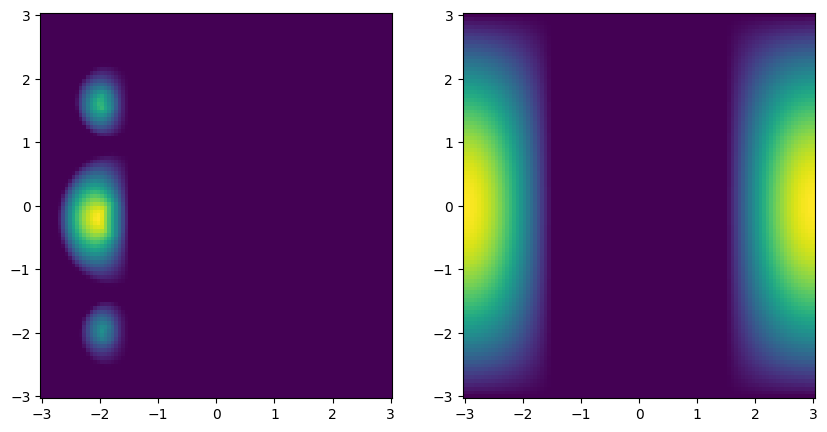

In [64]:
device = "cpu"

img = plt.imread('assets/test_distributions/dist_one_side.png')[:, :, 0] # Specify the path to your image here

target = LambertConditionedImagePrior(img)

grid_size = 100

normal = torch.Tensor([1, 0, 0])

# unnorm = torch.rand(3)
# normal = torch.divide(unnorm, torch.norm(unnorm))


# Plot prior distribution
xx, yy = torch.meshgrid(torch.linspace(-3, 3, grid_size), torch.linspace(-3, 3, grid_size))
zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)
zz = zz.double().to(device)

normals = normal.expand((zz.shape[0],) + (3,))
z_ = torch.clamp((zz + 3) / 6, max=1, min=0)
vecs = utils.points_to_unit_sphere(z_)

sum = normals * vecs
dots = torch.clamp(torch.sum(sum, dim = 1), min = 0)

log_prob = target.log_prob(zz, normals)

prob = torch.exp(log_prob.to('cpu').view(*xx.shape))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

ax1.pcolormesh(xx, yy, prob.data.numpy())
ax2.pcolormesh(xx, yy, dots.to('cpu').view(*xx.shape).data.numpy())

plt.show()

In [33]:
# Set up model

# Define flows
K = 8
torch.manual_seed(0)

latent_size = 2
hidden_units = 128
hidden_layers = 2

mask = np.array([1, 0])

flows = []
for i in range(K):
    flows += [ConditionedRVPFlow(mask, 64, 3)]
    mask = 1 - mask



# Set target and base distribution
img = plt.imread('assets/test_distributions/dist_one_side.png')[:, :, 0] # Specify the path to your image here
target = LambertConditionedImagePrior(img)
q0 = nf.distributions.DiagGaussian(2)

# q0 = nf.distributions.base.Uniform([1, 1], low = -3, high = 3)

# Construct flow model
nfm = ConditionedNormalizingFlow(q0=q0, flows=flows, p=target)

# Move model on GPU if available
enable_cuda = False
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')
nfm = nfm.to(device)
nfm = nfm.double()

 25%|██▍       | 2497/10000 [00:50<02:27, 50.78it/s]

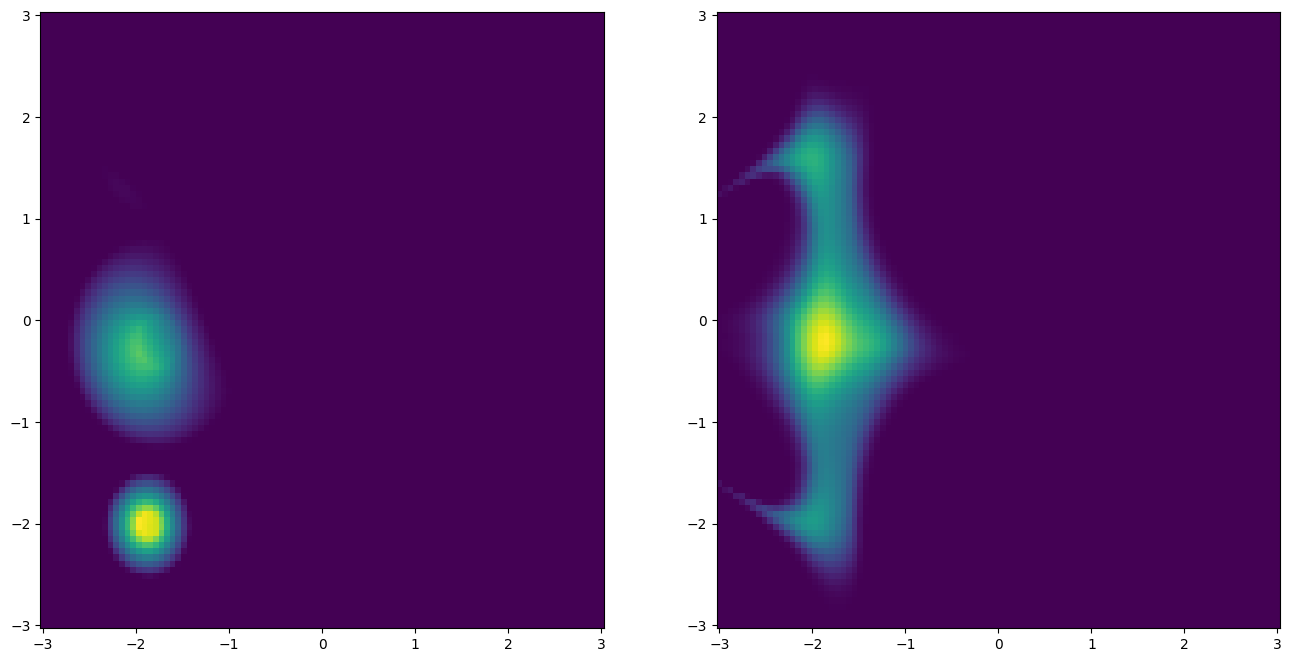

 50%|████▉     | 4999/10000 [01:41<01:39, 50.06it/s]

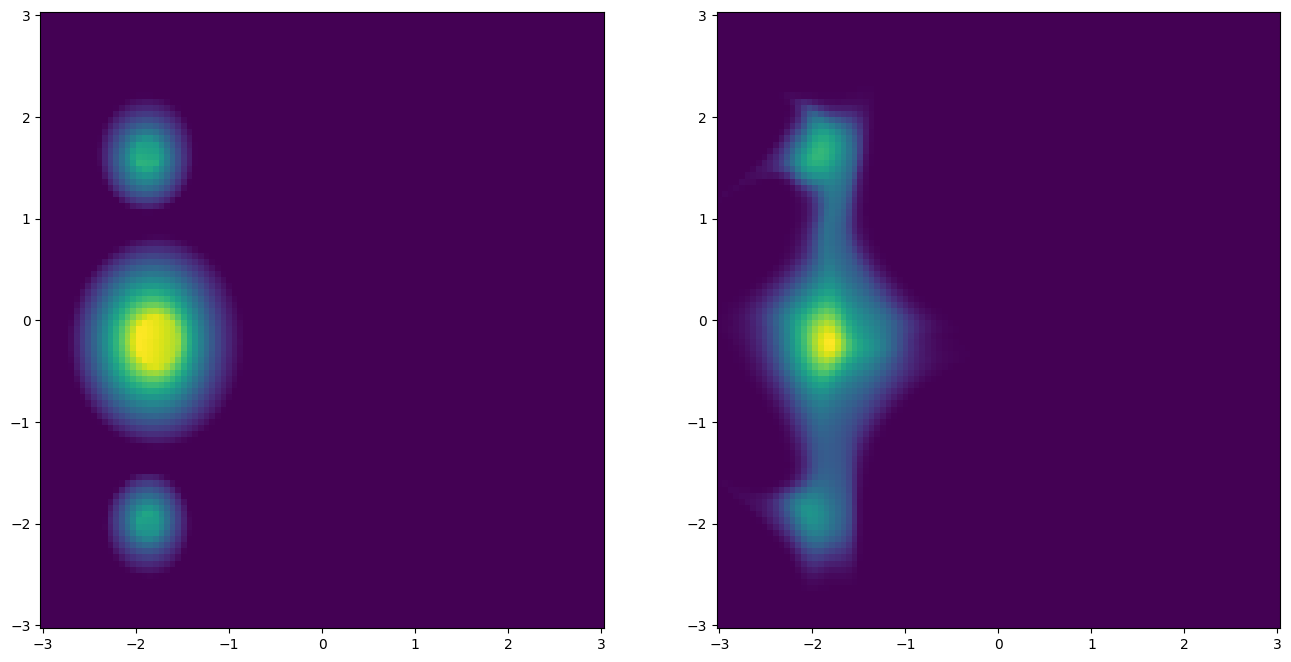

 75%|███████▍  | 7499/10000 [02:33<00:51, 48.63it/s]

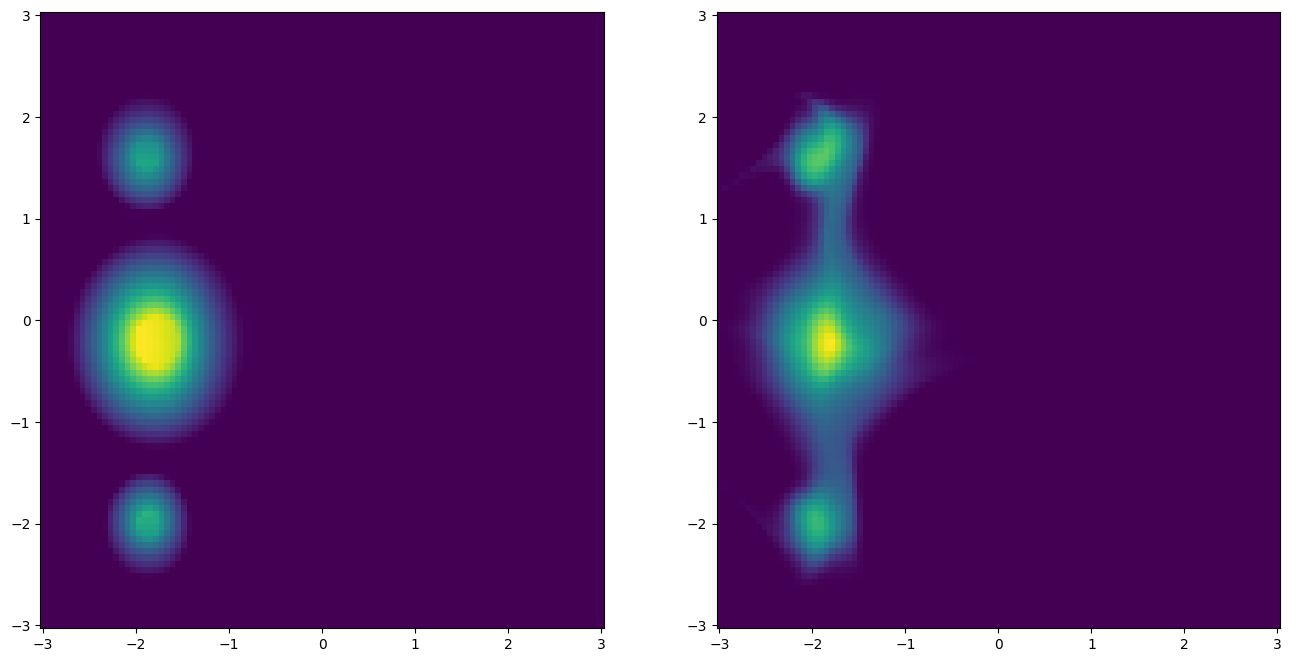

100%|█████████▉| 9996/10000 [03:25<00:00, 48.86it/s]

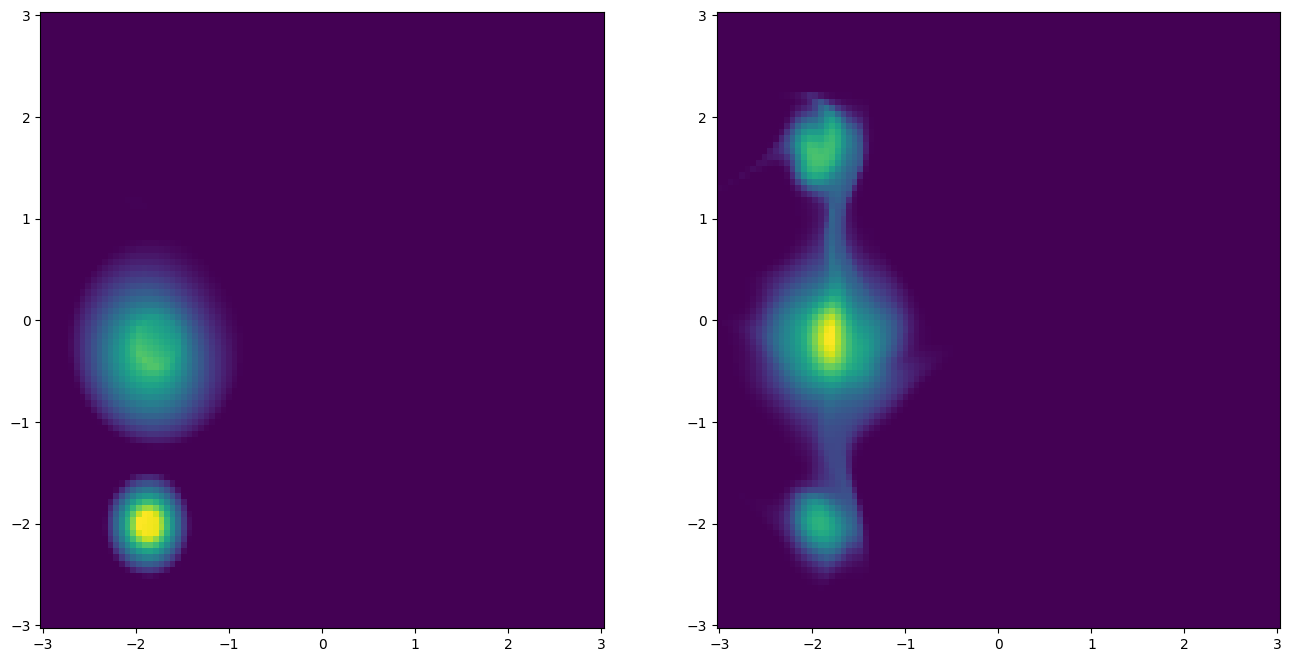

100%|██████████| 10000/10000 [03:26<00:00, 48.35it/s]


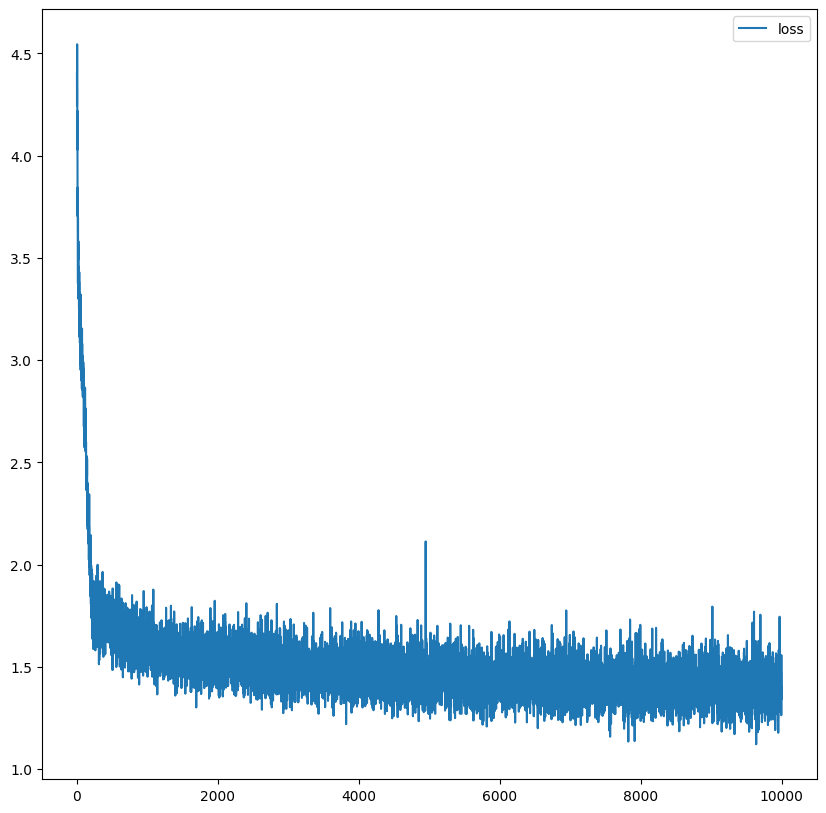

In [34]:
# Train model
max_iter = 10000
num_samples = 2 ** 6
show_iter = 2500


loss_hist = np.array([])

optimizer = torch.optim.AdamW(nfm.parameters(), lr=1e-4, weight_decay=1e-4)
for it in tqdm.tqdm(range(max_iter)):
    optimizer.zero_grad()

    unnorm = torch.rand(3)
    normal = torch.divide(unnorm, torch.norm(unnorm))

    x = nfm.p.sample(num_samples = num_samples, normal = normal).double()

    # loss = nfm.forward_kld(x)
    log_probs = nfm.log_prob(x, context = normal)
    loss = -torch.mean(log_probs[~torch.isinf(log_probs)])
    
    if ~(torch.isnan(loss) | torch.isinf(loss)):
        loss.backward()
        optimizer.step()
        loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())
    
    # Plot learned distribution
    if (it + 1) % show_iter == 0:
        compare_model_normal(nfm, device, normal)

plt.figure(figsize=(10, 10))
plt.plot(loss_hist, label='loss')
plt.legend()
plt.show()

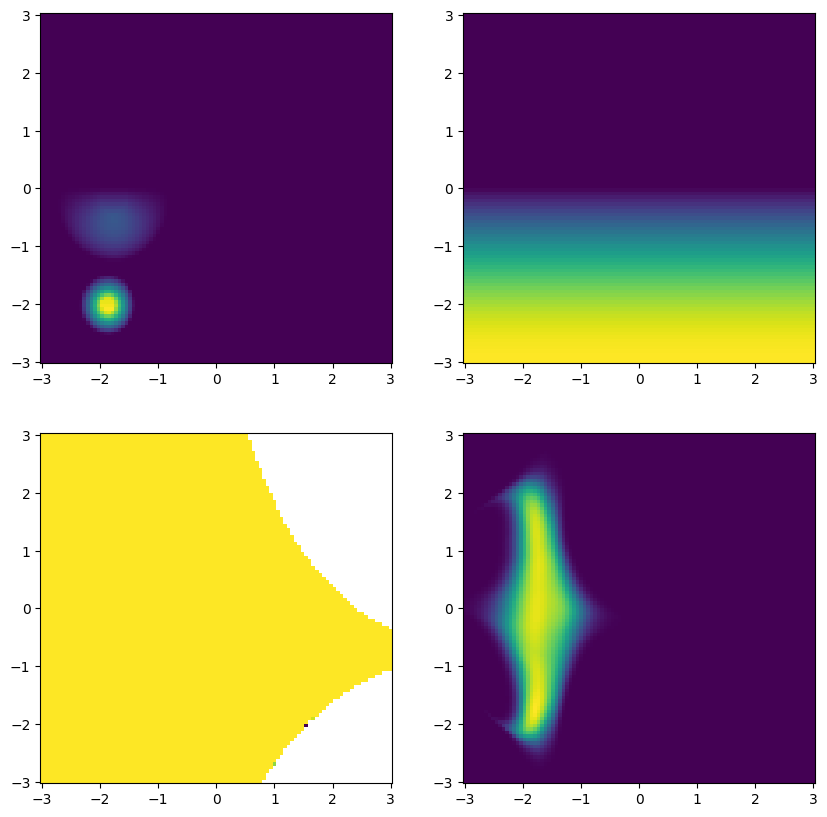

In [196]:
grid_size = 100

normal = torch.Tensor([0, 0, 1])

# unnorm = torch.rand(3)
# normal = torch.divide(unnorm, torch.norm(unnorm))

# Plot prior distribution
xx, yy = torch.meshgrid(torch.linspace(-3, 3, grid_size), torch.linspace(-3, 3, grid_size))
zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)
zz = zz.double().to(device)

normals = normal.expand((zz.shape[0],) + (3,))
z_ = torch.clamp((zz + 3) / 6, max=1, min=0)
vecs = utils.points_to_unit_sphere(z_)

sum = normals * vecs
dots = torch.clamp(torch.sum(sum, dim = 1), min = 0)

log_prob = target.log_prob(zz, normals)

prob = torch.exp(log_prob.to('cpu').view(*xx.shape))

log_pred = nfm.log_prob(zz, normal)
log_pred[torch.isnan(log_pred)] = -torch.inf
pred = torch.exp(log_pred.to('cpu').view(*xx.shape))

fig, axs = plt.subplots(2, 2, figsize=(10, 10))

axs[0, 0].pcolormesh(xx, yy, prob.data.numpy())
axs[0, 1].pcolormesh(xx, yy, dots.to('cpu').view(*xx.shape).data.numpy())
axs[1, 0].pcolormesh(xx, yy, log_pred.to('cpu').view(*xx.shape).data.numpy())
axs[1, 1].pcolormesh(xx, yy, pred.data.numpy())

plt.show()

# Quadratic Rational Conditioned

In [4]:
from math import sqrt, pi

class EncodedNFM(nf.ConditionalNormalizingFlow):
    def __init__(self, q0, flows, p = None):
        super().__init__(q0, flows, p)
        # self.encodingDim = encodingDim
        # self.encoder = torch.nn.Sequential(torch.nn.Linear(in_features=2, out_features=encodingDim), torch.nn.ReLU())
        # self.decoder = torch.nn.Sequential(torch.nn.Linear(in_features=encodingDim, out_features=2). torch.nn.ReLU())

    def log_prob(self, x, context=None):
        """Get log probability for batch

        Args:
          x: Batch
          context: Batch of conditions/context

        Returns:
          log probability
        """

        log_q = torch.zeros(len(x), dtype=x.dtype, device=x.device)
        z = x
        for i in range(len(self.flows) - 1, -1, -1):
            z, log_det = self.flows[i].inverse(z, context=context)
            log_q += log_det

        log_q += self.q0.log_prob(z, context=context)
        return log_q

def one_blob_encoding_stack(mu, K = 16):
    sigma = 1 / K
    bins = np.arange(sigma / 2, 1, sigma) # create K bins with each bin value being its center
    return 1 / (sigma * sqrt(2 * pi)) * np.exp(-0.5 * np.square(bins - mu[: , None]) / np.square(sigma))

def one_blob_encoding(mu_list, K=16):
    mu_array = torch.asarray(mu_list)  # shape (N,)
    sigma = 1 / K
    bins = torch.arange(sigma / 2, 1, sigma)  # shape (K,)

    # Reshape for broadcasting: (N, 1) - (1, K) => (N, K)
    # diffs = bins[None, :] - mu_array[:, None]
    diffs = mu_list[..., None] - bins
    weights = torch.exp(-0.5 * (diffs ** 2) / sigma**2)
    weights = weights / (sigma * sqrt(2 * pi))

    return weights.reshape(mu_list.shape[0], -1)  # (M, N * K)

In [ ]:
mu = np.array([0.5, 0.1])
K = 32

enc = one_blob_encoding(mu, K)
# print(enc)
# print(enc.reshape(-1))

fig, ax = plt.subplots(1, 1, figsize=(3, 3))
ax.bar(range(0, len(mu) * K), enc)
# ax.bar(range(0, K), enc[0] + enc[1])
# ax.bar(range(0, K), )

In [29]:
K = 8
torch.manual_seed(0)

use_one_blob = False

### Used for non-encoded
latent_size = 2

# latent_size = 16

hidden_units = 64
hidden_layers = 1

context_size = 3
context_channels = context_size
if use_one_blob:
    context_bin_count = 32
    context_channels = context_size * context_bin_count

mask = np.array([1, 0])

flows = []
for i in range(K):
    # flows += [RealNVPFlow(mask, 64)]
    # mask = 1 - mask
    flows += [nf.flows.AutoregressiveRationalQuadraticSpline(
        latent_size, 
        hidden_layers, 
        hidden_units,
        num_context_channels=context_channels, 
        permute_mask=True)]
    # flows += [nf.flows.LULinearPermute(latent_size)]

enable_cuda = False
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')
print(torch.cuda.is_available())


# Set target and base distribution
# img = plt.imread('assets/test_distributions/complex.jpg')[:, :, 0] # Specify the path to your image here
img = plt.imread('assets/test_distributions/Checkerboard.png') # Specify the path to your image here
target = LambertConditionedImagePrior(img)
# q0 = nf.distributions.DiagGaussian(2)

low = np.float64(-3.0) 
high = np.float64(3.0)
# low = torch.tensor([-3.0], device = device).type(torch.float64)
# high = torch.tensor([3.0], device = device).type(torch.float64)
q0 = nf.distributions.base.Uniform(2, low = low, high = high)

q0.to(device)

# q0.low = q0.low.to(device)
# q0.high = q0.high.to(device)
# q0.log_prob_val = q0.log_prob_val.to(device)

# Construct flow model

if use_one_blob:
    nfm = EncodedNFM(q0 = q0, flows = flows, p = target)
else:
    nfm = nf.ConditionalNormalizingFlow(q0=q0, flows=flows, p=target)

# Move model on GPU if available
nfm = nfm.to(device)
nfm = nfm.double()

True


  0%|          | 0/1000 [00:00<?, ?it/s]

 25%|██▍       | 249/1000 [02:08<00:41, 18.02it/s]  

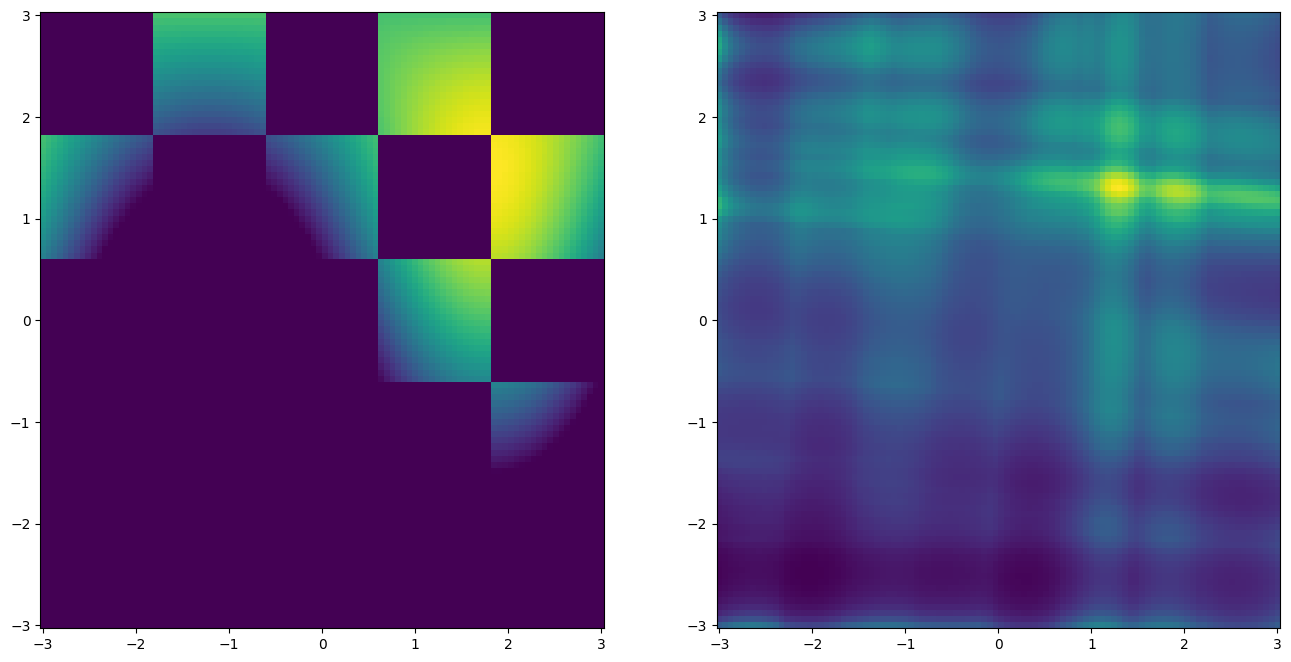

 29%|██▊       | 287/1000 [02:10<05:25,  2.19it/s]


KeyboardInterrupt: 

In [30]:
# Train model
max_iter = 1000
num_samples = 2 ** 8
show_iter = 250


loss_hist = np.array([])

### This is without encoder/decoder
optimizer = torch.optim.AdamW(nfm.parameters(), lr=1e-4, weight_decay=1e-2)

#optimizer = torch.optim.AdamW(
#    list(nfm.parameters())
#    + list(encoder.parameters())
#    + list(decoder.parameters()), 
#    lr=1e-4, weight_decay=1e-2)


for it in tqdm.tqdm(range(max_iter)):
    optimizer.zero_grad()

    unnorm = torch.rand(3, dtype=torch.float64, device = device) * 2 - 1
    normal = torch.divide(unnorm, torch.norm(unnorm))
    # normals = normal.expand((num_samples, 3))

    """ ----- Sampling ----- """

    ### Sampling target for cross entropy loss 
    # x = nfm.p.sample(num_samples = num_samples, normals = normals).to(device).double()

    ### Test: Sampling Uniformly for D_KL Loss
    x = nfm.q0.sample(num_samples = num_samples).type(torch.float64)

    normals = normal.expand((*x.shape[: -1], ) + (normal.shape[0], ))

    # normal_blob = one_blob_encoding(normal, context_bin_count)
    # normals = normal_blob.expand((*x.shape[: -1], ) + (normal_blob.shape[0], ))

    # TODO Check if I can use KL divergence on uniformly sampled points here
    # Would allow me to better use normal conditioning for when the normal conditioning
    # would reduce the entire pdf to 0 (or very close to it if the upper bound is really large)

    # End results seem to keep undershooting ?
    # Might want to put both reference and result on the same scale ? 
    # Doesn't change the distribution though

    """ ----- Loss Calculation -----"""
    
    ### Loss: Calculating forward KLD using implicit value for p(x) through sampling 
    # loss = nfm.forward_kld(, context = normals)

    # log_probs = nfm.log_prob(x, context = normals)
    # loss = -torch.mean(log_probs[~torch.isinf(log_probs)])
    
    
    ### Test: Calculating D_KL as loss directly

    log_probs_p = nfm.p.log_prob(x, normals = normals)
    probs_q = torch.exp(log_probs_p)
    ### Get this one for free when sampling from model
    log_probs_q = nfm.log_prob(x, context = normals)
    
    ### Since p is independent of the weights, the following calculation of kl_divs are equivalent 
    ### Given a fixed seed they produce the exact same results
    # kl_divs = probs_q * (log_probs_p - log_probs_q)
    kl_divs = -probs_q * log_probs_q
    loss = torch.mean(kl_divs[~(torch.isnan(kl_divs) | torch.isinf(kl_divs))])


    if ~(torch.isnan(loss) | torch.isinf(loss)):
        loss.backward()
        optimizer.step()
        loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())
    
    # Plot learned distribution
    if (it + 1) % show_iter == 0:
        compare_model_normal(nfm, device, normal)

plt.figure(figsize=(10, 10))
plt.plot(loss_hist, label='loss')
plt.legend()
plt.show()

<BarContainer object of 101 artists>

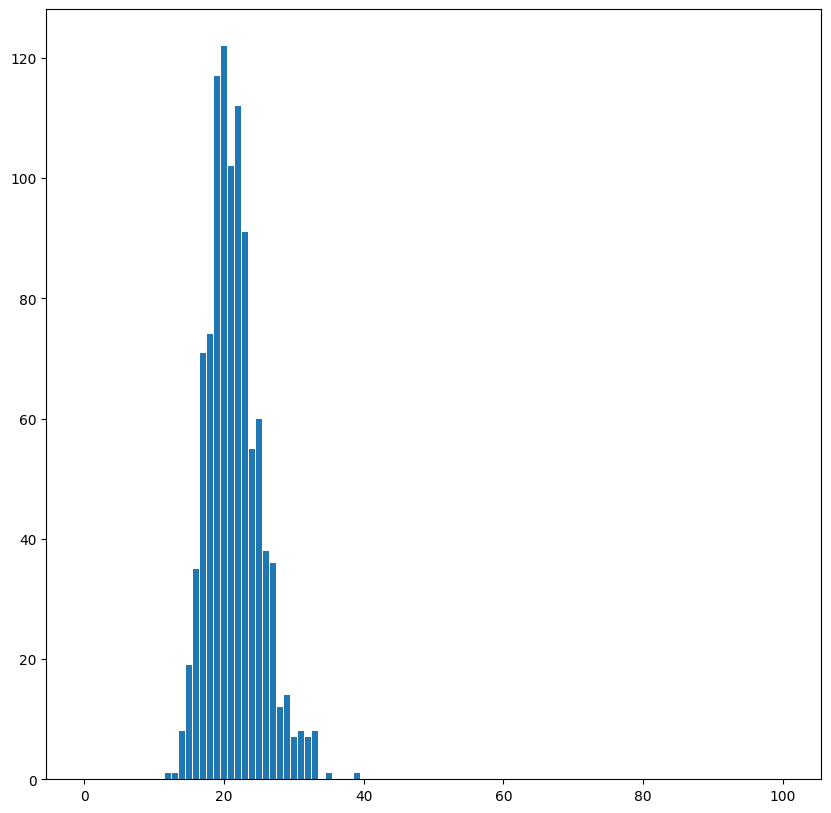

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

ax.bar(range(0, 101), nfm.p.iterations_count)

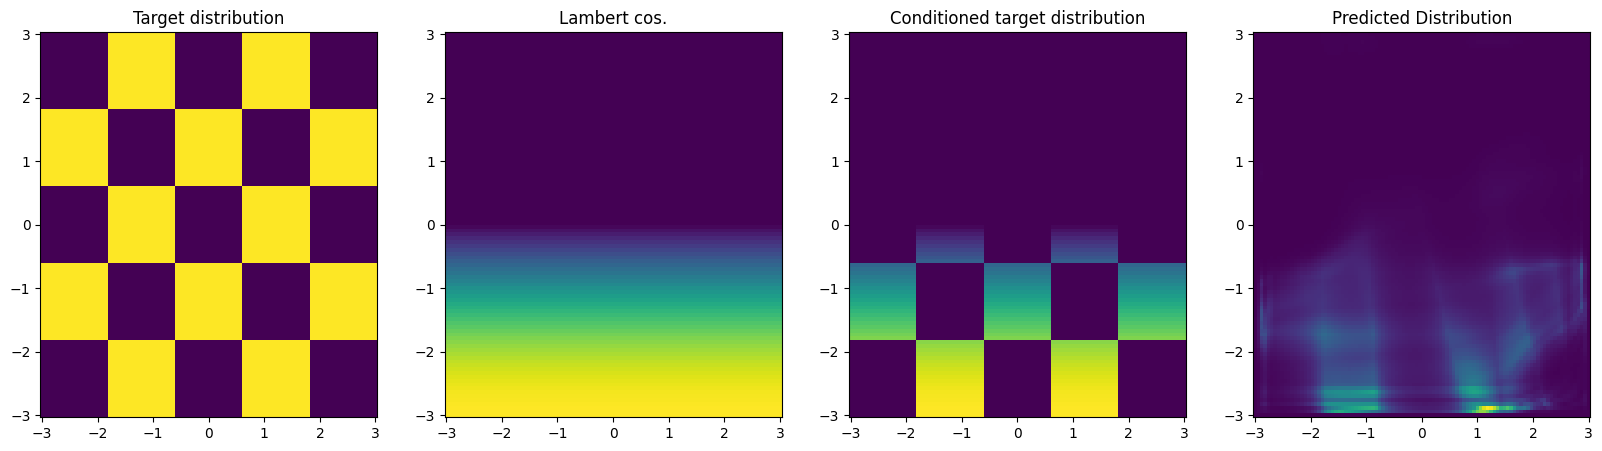

In [13]:
grid_size = 100

normal = torch.Tensor([0, 0, -1]).type(dtype=torch.float64)

# unnorm = torch.rand(3, dtype=torch.float64)
# normal = torch.divide(unnorm, torch.norm(unnorm))

# Plot prior distribution
xx, yy = torch.meshgrid(torch.linspace(-3, 3, grid_size), torch.linspace(-3, 3, grid_size))
zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)
zz = zz.double().to(device)

normals = normal.expand((zz.shape[0],) + (3,))
z_ = torch.clamp((zz + 3) / 6, max=1, min=0)
vecs = utils.points_to_unit_sphere(z_)

sum = normals * vecs
dots = torch.clamp(torch.sum(sum, dim = 1), min = 0)

uncond_log_prob = target.log_prob(zz)
log_prob = target.log_prob(zz, normals)

uncond_prob = torch.exp(uncond_log_prob.to('cpu').view(*xx.shape))
uncond_prob[uncond_prob < 1e-9] = 0

prob = torch.exp(log_prob.to('cpu').view(*xx.shape))
prob[prob < 1e-9] = 0

log_pred = nfm.log_prob(zz, normals)
log_pred[torch.isnan(log_pred)] = -torch.inf
pred = torch.exp(log_pred.to('cpu').view(*xx.shape))

fig, axs = plt.subplots(1, 4, figsize=(20, 5))

axs[0].pcolormesh(xx, yy, uncond_prob.data.numpy())
axs[0].set_title("Target distribution")
axs[1].pcolormesh(xx, yy, dots.to('cpu').view(*xx.shape).data.numpy())
axs[1].set_title("Lambert cos.")
axs[2].pcolormesh(xx, yy, prob.data.numpy())
axs[2].set_title("Conditioned target distribution")
axs[3].pcolormesh(xx, yy, pred.data.numpy())
axs[3].set_title("Predicted Distribution")
# axs[1, 0].pcolormesh(xx, yy, log_pred.to('cpu').view(*xx.shape).data.numpy())
# axs[1, 1].pcolormesh(xx, yy, pred.data.numpy())

plt.show()

IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

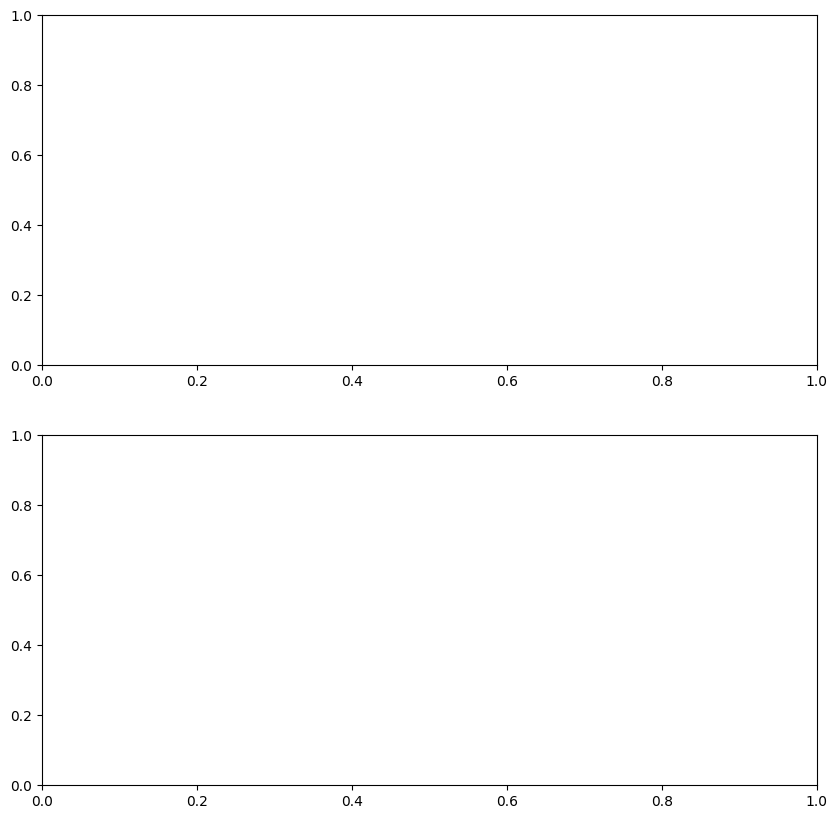

In [10]:
grid_size = 100

normal = torch.Tensor([0, 0, -1]).type(dtype=torch.float64)

# unnorm = torch.rand(3, dtype=torch.float64)
# normal = torch.divide(unnorm, torch.norm(unnorm))

# Plot prior distribution
xx, yy = torch.meshgrid(torch.linspace(-3, 3, grid_size), torch.linspace(-3, 3, grid_size))
zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)
zz = zz.double().to(device)

normals = normal.expand((zz.shape[0],) + (3,))
z_ = torch.clamp((zz + 3) / 6, max=1, min=0)
vecs = utils.points_to_unit_sphere(z_)

sum = normals * vecs
dots = torch.clamp(torch.sum(sum, dim = 1), min = 0)

x = nfm.p.sample(num_samples = num_samples, normal = normal).double()


fig, axs = plt.subplots(2, 1, figsize=(10, 10))

axs[0, 0].pcolormesh(xx, yy, dots.to('cpu').view(*xx.shape).data.numpy())
axs[0, 1].scatter(x[:, 0], x[:, 1], color="blue", marker="o")


plt.show()

In [28]:

def apply_cosine(img, normal):
    out = np.zeros_like(img)
    lambert_cos = np.zeros_like(img)
    dims = np.flip(np.array(img.shape))
    shape = np.array(img.shape)
    for y in range(len(img)):
        for x in range(len(img[y])):
            uvs = np.array([x, y]) / dims
            dir = utils.point_to_unit_sphere(uvs).numpy()
            dot_prd = np.dot(dir, normal)
            out[y][x] = img[y][x] * dot_prd
            lambert_cos[y][x] = dot_prd
    return out, lambert_cos


img = plt.imread('assets/test_distributions/TestDist2.png')[:, :, 0] # Specify the path to your image here
normal = utils.normalize(np.random.rand(3) * 2 - 1)
# normal = [0, 0, 1]

img_applied, lambert = apply_cosine(img, normal)

# cv2.imshow("fade", arr)
cv2.imshow("img", img)
cv2.imshow("applied", img_applied)
cv2.imshow("lambert", lambert)
cv2.waitKey()
cv2.destroyAllWindows()

print(np.array(img.shape))


[500 800]


# Quadratic Rational

In [7]:
K = 8
torch.manual_seed(0)

latent_size = 2
hidden_units = 128
hidden_layers = 2

mask = np.array([1, 0])

flows = []
for i in range(K):
    # flows += [RealNVPFlow(mask, 64)]
    # mask = 1 - mask
    flows += [nf.flows.AutoregressiveRationalQuadraticSpline(
        latent_size, 
        hidden_layers, 
        hidden_units, 
        permute_mask=True)]
    # flows += [nf.flows.LULinearPermute(latent_size)]

# Move model on GPU if available
enable_cuda = True
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')


# Set target and base distribution
# img = plt.imread('assets/test_distributions/complex.jpg')[:, :, 0] # Specify the path to your image here
img = plt.imread('assets/test_distributions/Checkerboard.png') # Specify the path to your image here
target = nf.distributions.ImagePrior(img, x_range=[0, 1], y_range=[0, 1])
prior_eps = 1.0e-10
# q0 = nf.distributions.DiagGaussian(2)
# q0 = nf.distributions.base.Uniform(2, low = np.float64(-3.0), high = np.float64(3.0))

low = torch.tensor([-3.0]).type(torch.float64)
high = torch.tensor([3.0]).type(torch.float64)
# q0 = nf.distributions.base.Uniform(2, low = low, high = high)
# q0 = Uniform(2, low = low, high = high, device = device)
q0 = GMM(12).double().to(device)

# Construct flow model
nfm = nf.NormalizingFlow(q0=q0, flows=flows, p=target)

nfm = nfm.to(device)
nfm = nfm.double()

print(device)

cuda


In [11]:
def train_GMM(target: nf.distributions.ImagePrior, model: GMM, its = 300, regu_factor = 0.5):
    num_samples = 2**12
    losses = []
    keep_regu = its * regu_factor

    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-2, weight_decay=1e-4)
    for it in tqdm.tqdm(range(its)):
        optimizer.zero_grad()

        x = torch.rand((num_samples, 2), device=device)

        log_prob_p = target.log_prob(x)
        log_prob_q = model.log_prob(x)

        prob_p = torch.exp(log_prob_p)
        prob_q = torch.exp(log_prob_q)

        KLD_loss = -torch.mean(prob_p * log_prob_q)
        # rKLD_loss = torch.mean(prob_q * (log_prob_q - log_prob_p))

        loss = KLD_loss
        # loss = rKLD_loss
        
        if it == keep_regu:
            optimizer = torch.optim.AdamW(model.parameters(), lr=1e-2, weight_decay=1e-4)

        if it < keep_regu:
            L2_weights = torch.nn.functional.softmax(model.weight_logits, dim = 0).square().sum()
            # L2_weights = model.weight_logits.exp().square().sum()
            loss += L2_weights
        else:
            losses.append(loss.mean().item())
        # loss = KLD_loss

        
        loss.backward()

        if it < keep_regu:
            # model.weight_logits.grad.zero_()
            model.cholesky_params.grad.zero_()

        optimizer.step()

    return losses

train_GMM(target, q0, 300, regu_factor=0.5)

100%|██████████| 300/300 [00:01<00:00, 297.91it/s]


[4.54666021379591e-07,
 4.695539318239387e-07,
 4.572461225507323e-07,
 4.574732305446046e-07,
 4.4101152848091374e-07,
 4.60706753525788e-07,
 4.492988794355382e-07,
 4.4915260408134083e-07,
 4.4191234319794847e-07,
 4.367231240540867e-07,
 4.437030341254259e-07,
 4.3199898756823966e-07,
 4.25319068488448e-07,
 4.280741869390356e-07,
 4.331857454591069e-07,
 4.2275223192078886e-07,
 4.154096651086118e-07,
 4.0856586237268564e-07,
 4.24181664304148e-07,
 4.142788013356985e-07,
 3.897237660353979e-07,
 4.086874608182499e-07,
 3.912553531415546e-07,
 4.0864131783316506e-07,
 4.02910202319528e-07,
 3.883596392668617e-07,
 3.8569320646831275e-07,
 3.874391648959645e-07,
 3.9838074375505353e-07,
 3.807634158492613e-07,
 3.8463656315748477e-07,
 3.853247386530793e-07,
 3.7477303628968317e-07,
 3.807284842837938e-07,
 3.7363935395508167e-07,
 3.789368591701407e-07,
 3.674595252109298e-07,
 3.695591066745095e-07,
 3.5852850021521104e-07,
 3.564909857117759e-07,
 3.555203633897011e-07,
 3.55170

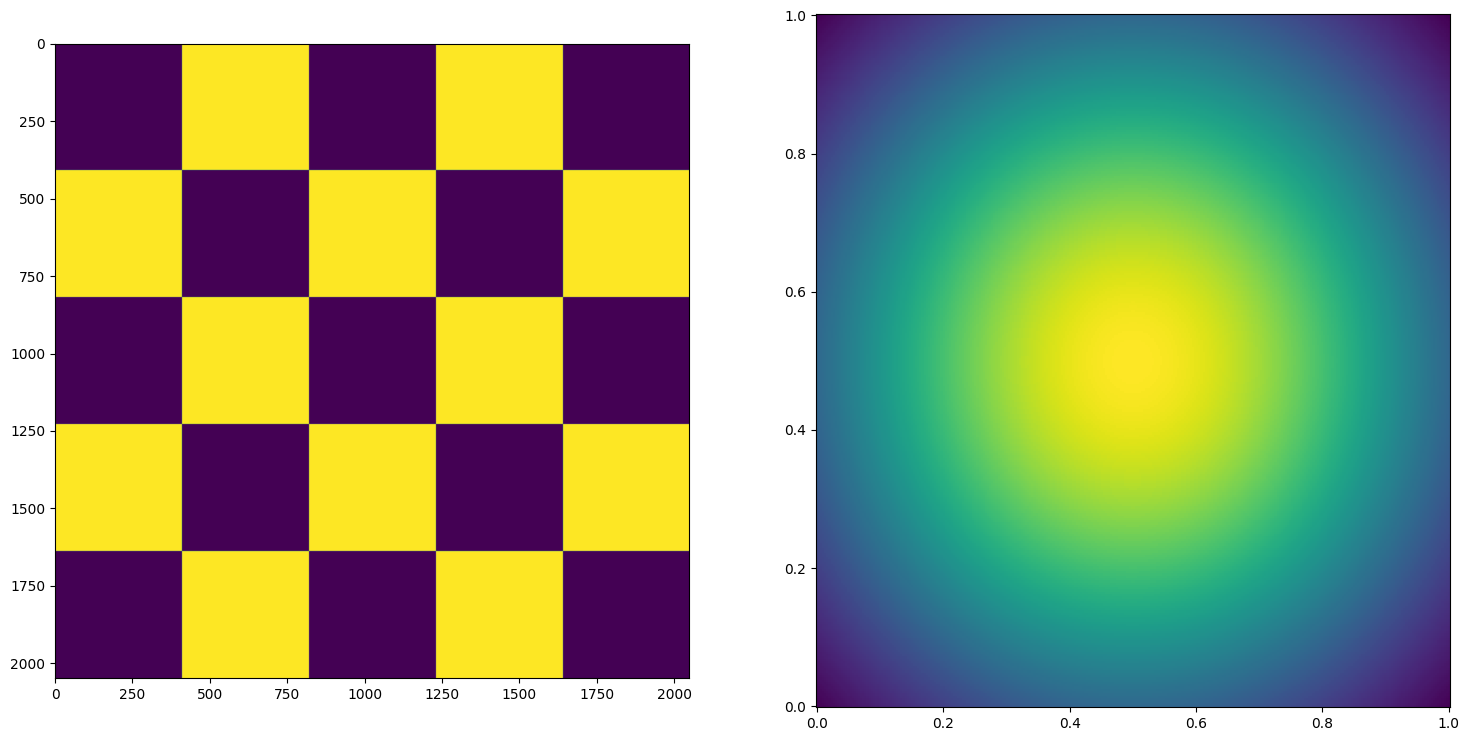

In [12]:
grid_size = 300

xs = torch.linspace(0, 1, grid_size)
ys = torch.linspace(0, 1, grid_size)
xx, yy = torch.meshgrid(xs, ys)
zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2).to(device=device)

log_probs = q0.prob(zz).view(*xx.shape)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 9))
ax1.imshow(img)
ax2.pcolormesh(xx, yy, log_probs.cpu().detach().numpy())
plt.show()

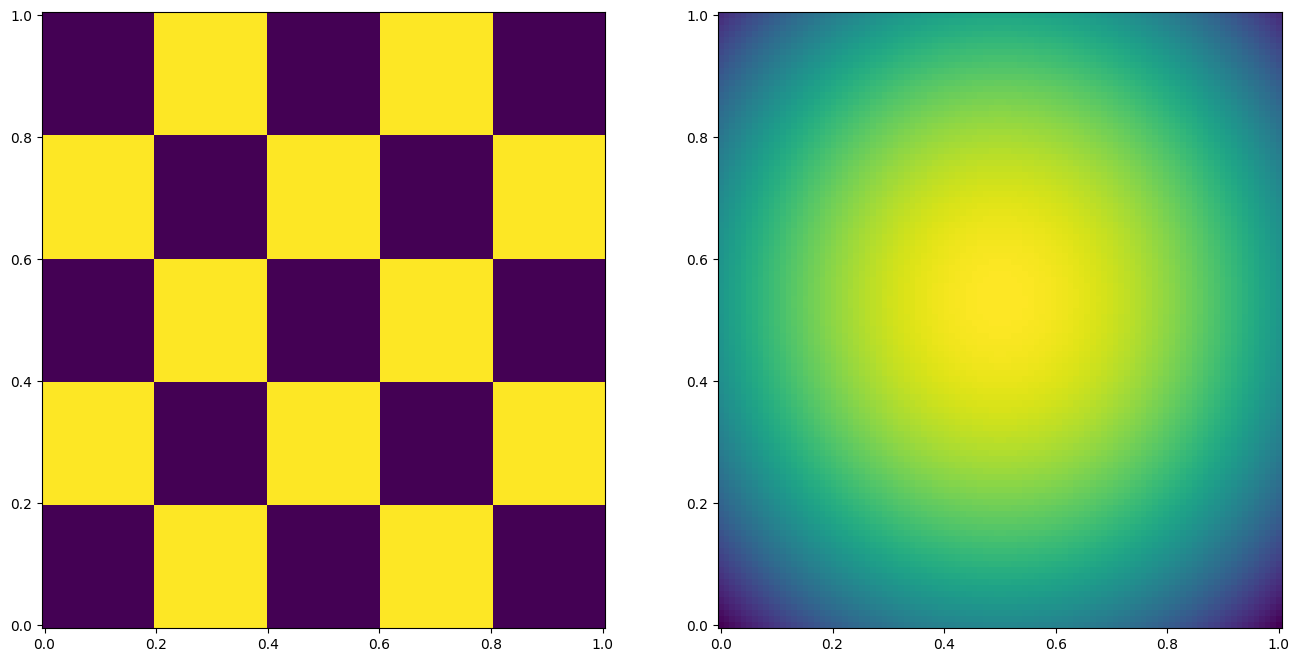

In [55]:
compare_model(nfm = nfm, device = device, low = 0.0, high = 1.0)

 10%|▉         | 99/1000 [00:19<02:52,  5.21it/s]

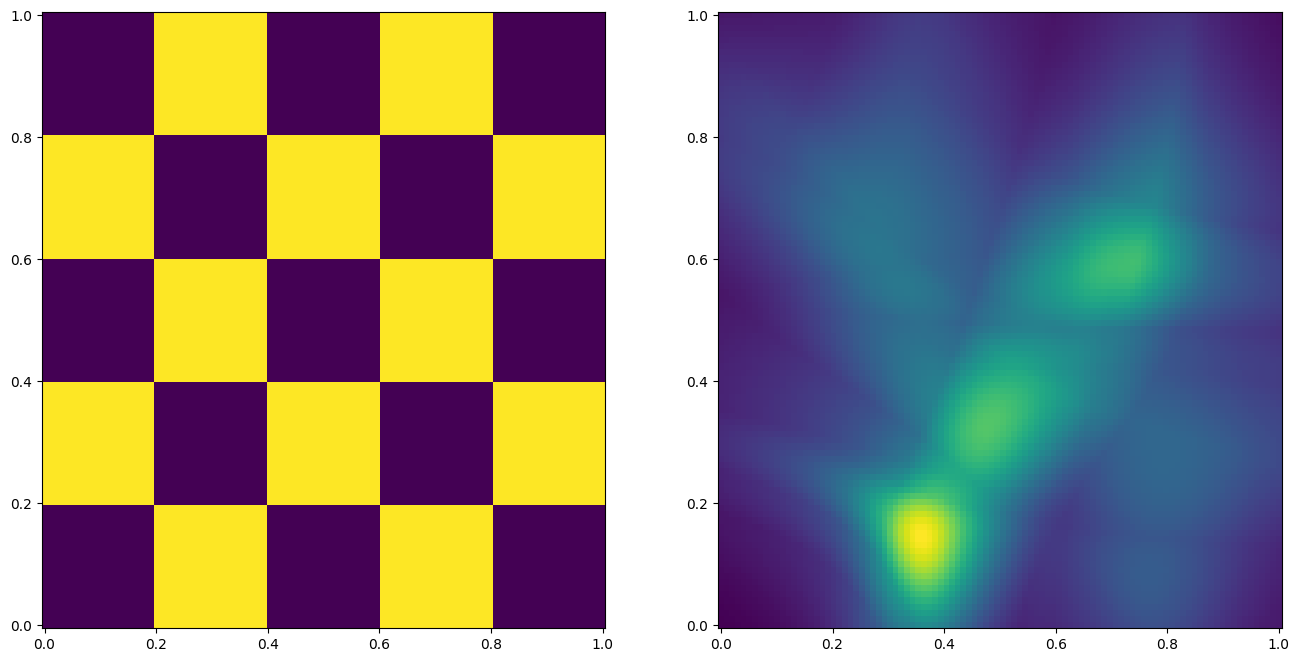

 20%|█▉        | 199/1000 [00:38<02:35,  5.17it/s]

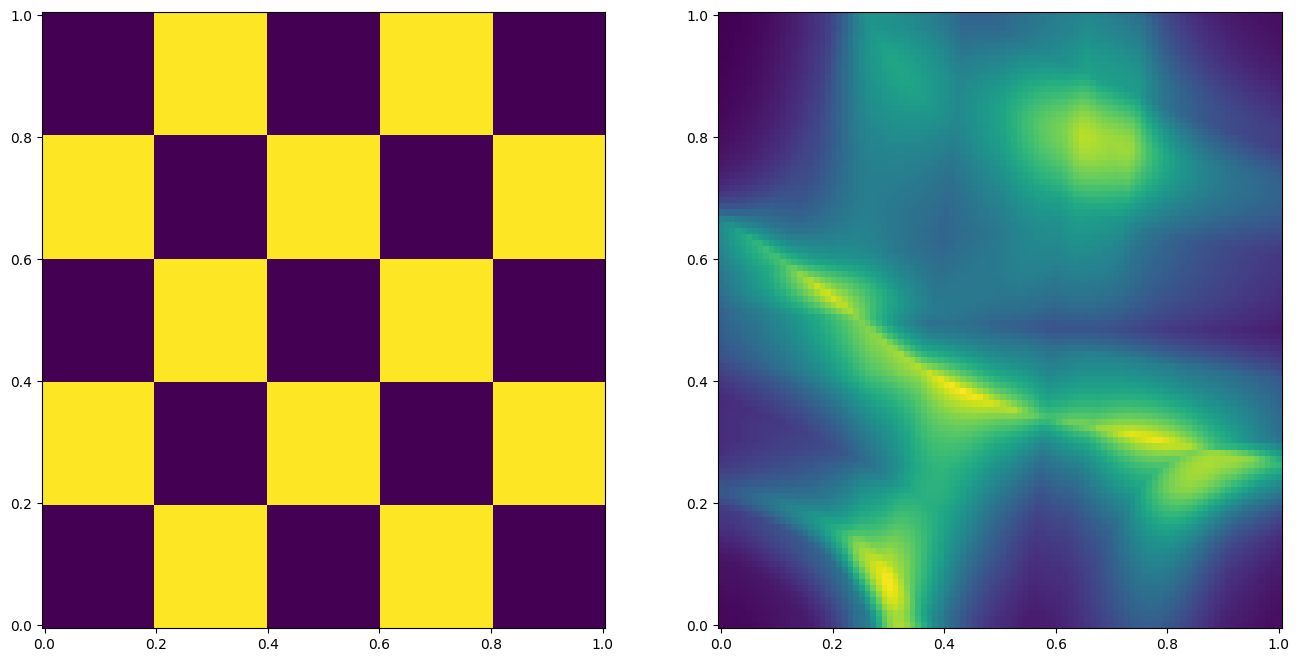

 30%|██▉       | 299/1000 [00:57<02:07,  5.48it/s]

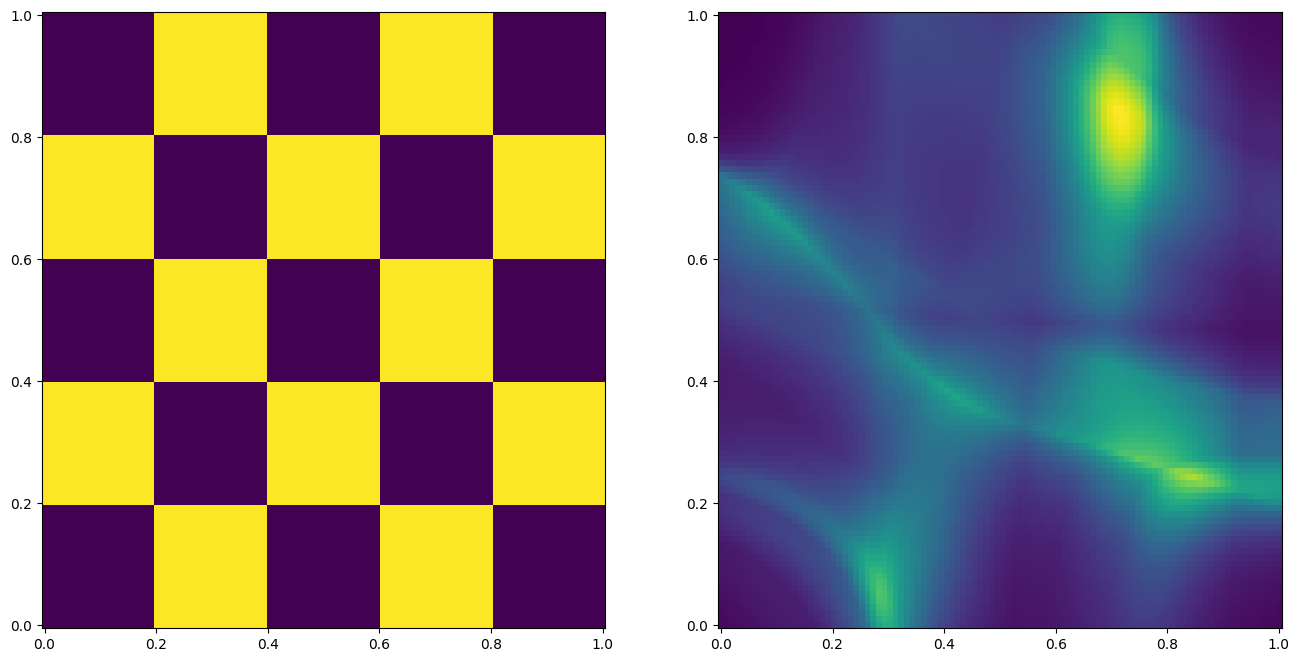

 40%|███▉      | 399/1000 [01:16<01:50,  5.42it/s]

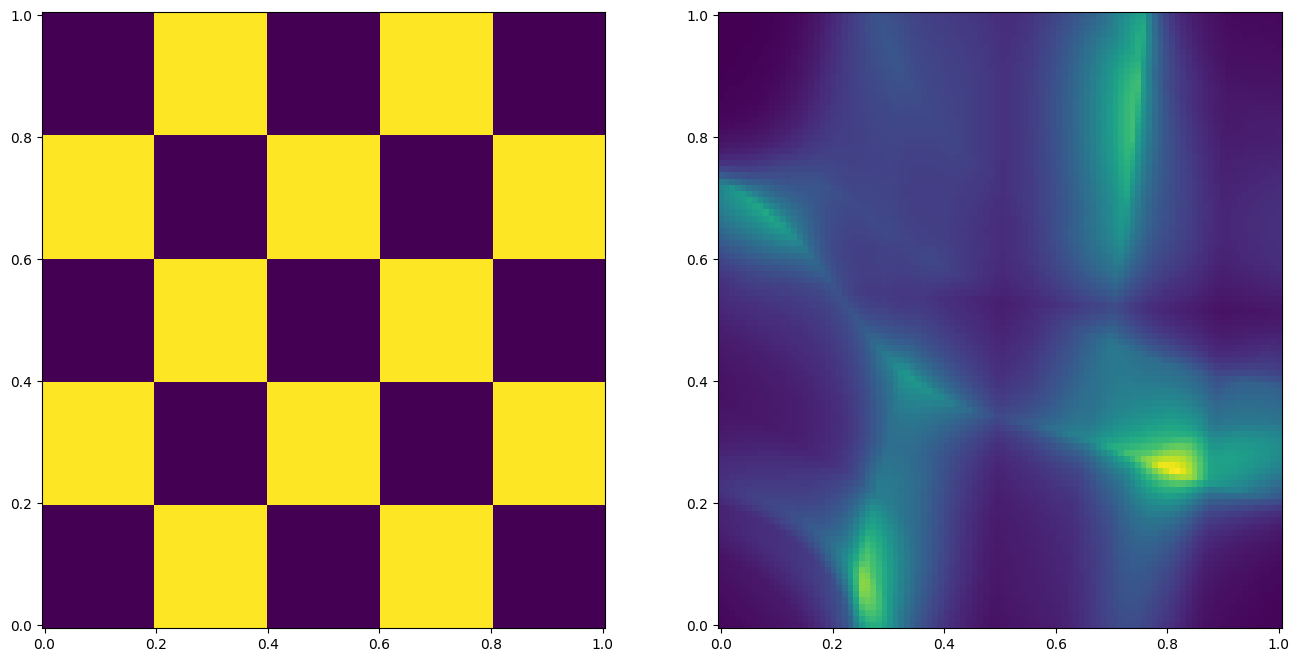

 50%|████▉     | 499/1000 [01:35<01:34,  5.28it/s]

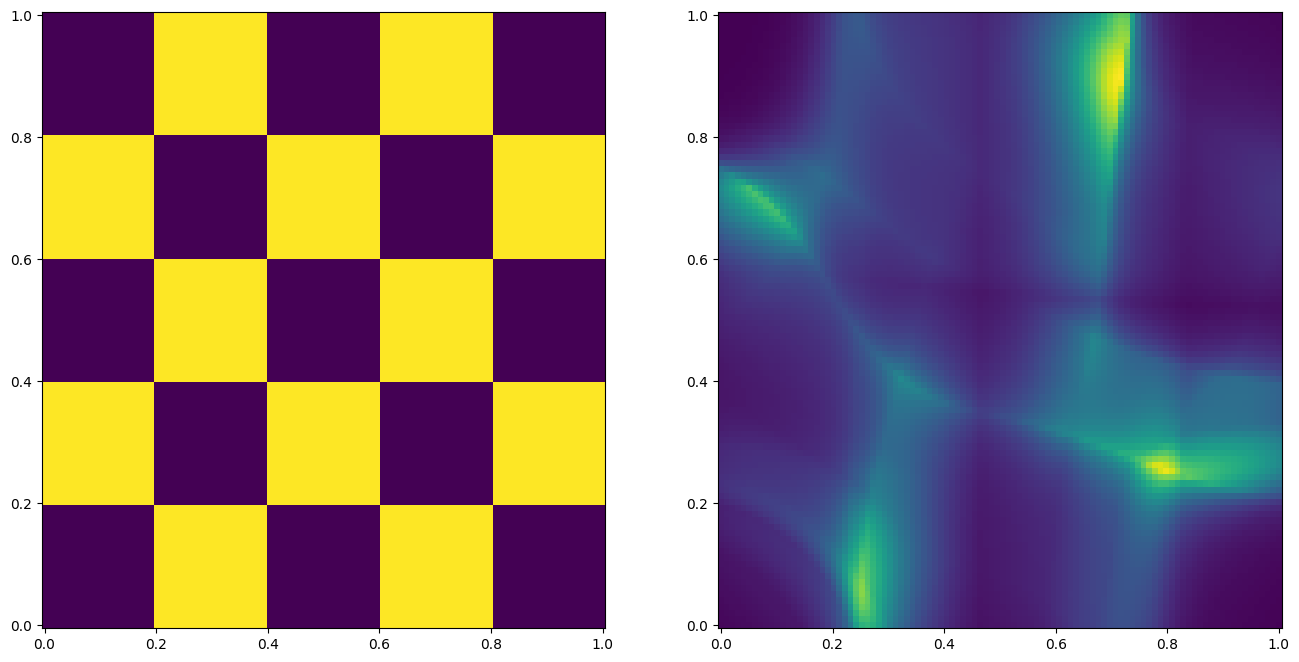

 60%|█████▉    | 599/1000 [01:54<01:14,  5.35it/s]

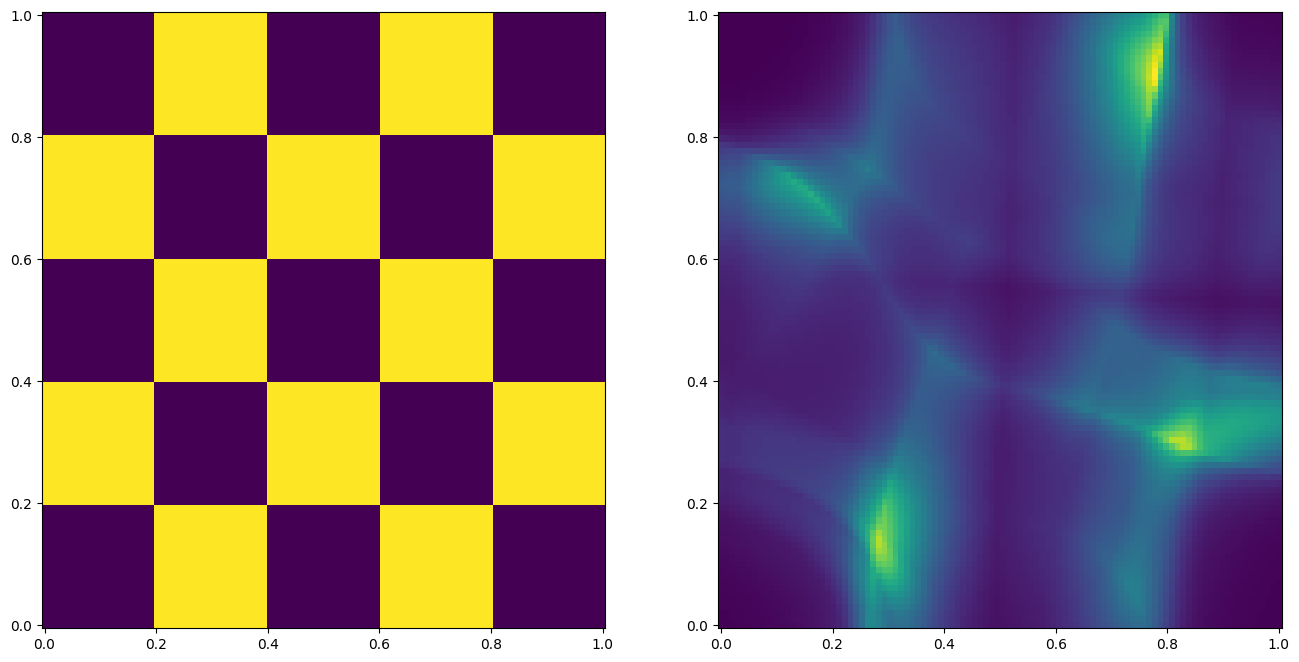

 70%|██████▉   | 699/1000 [02:14<00:57,  5.21it/s]

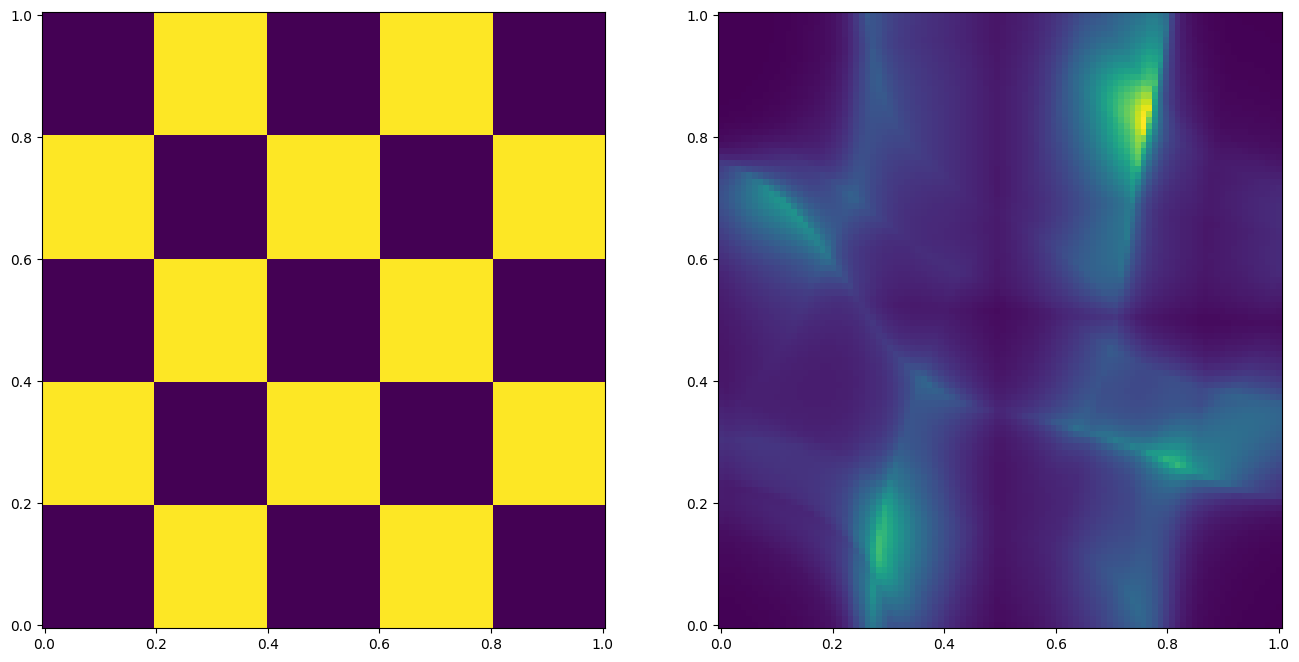

 80%|███████▉  | 799/1000 [02:33<00:39,  5.10it/s]

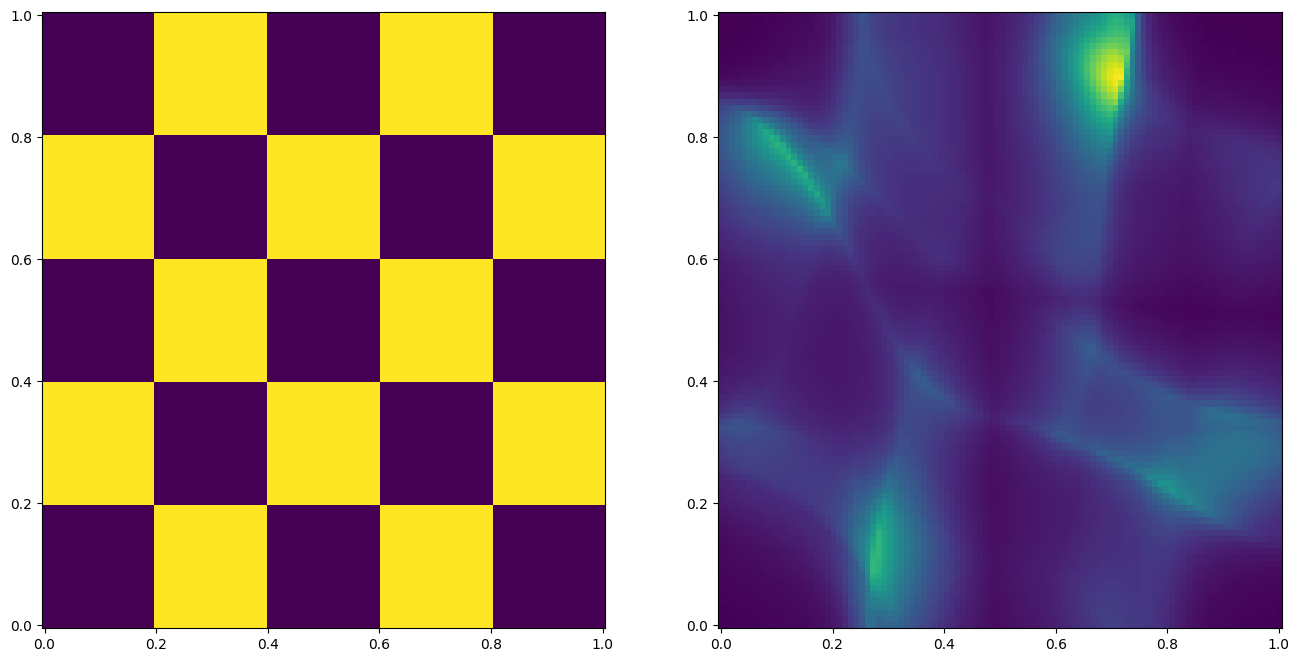

 90%|████████▉ | 899/1000 [02:53<00:19,  5.15it/s]

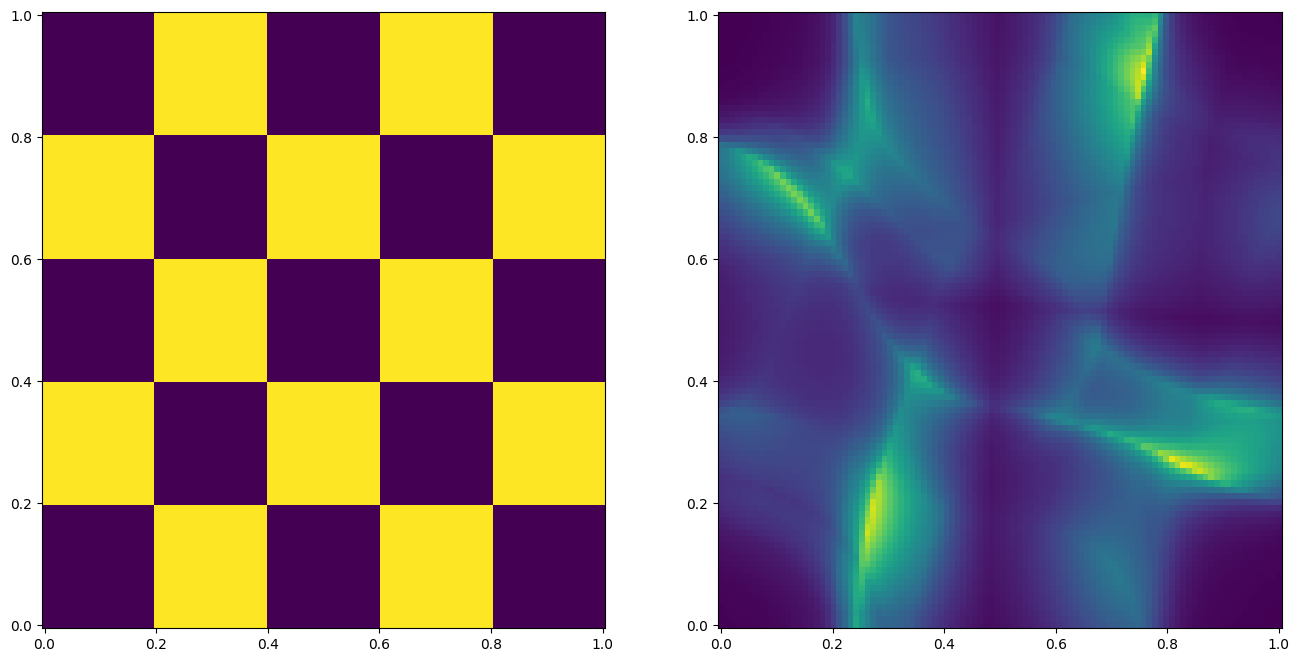

100%|█████████▉| 999/1000 [03:12<00:00,  5.15it/s]

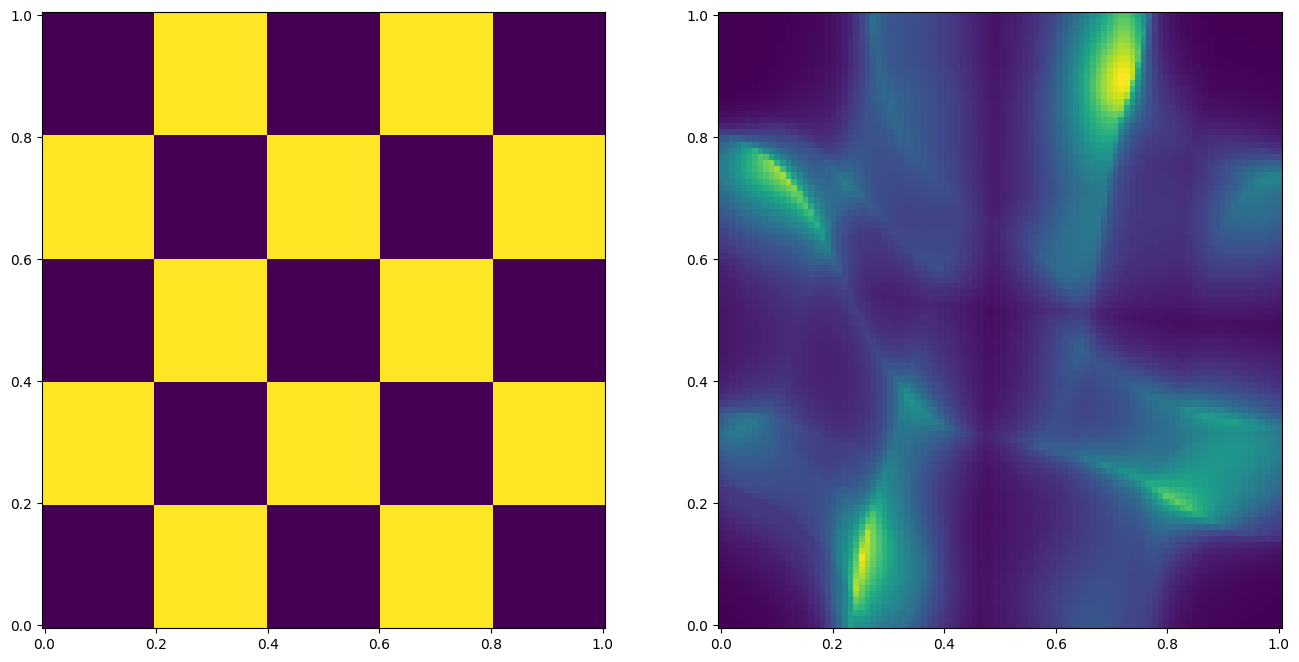

100%|██████████| 1000/1000 [03:13<00:00,  5.17it/s]


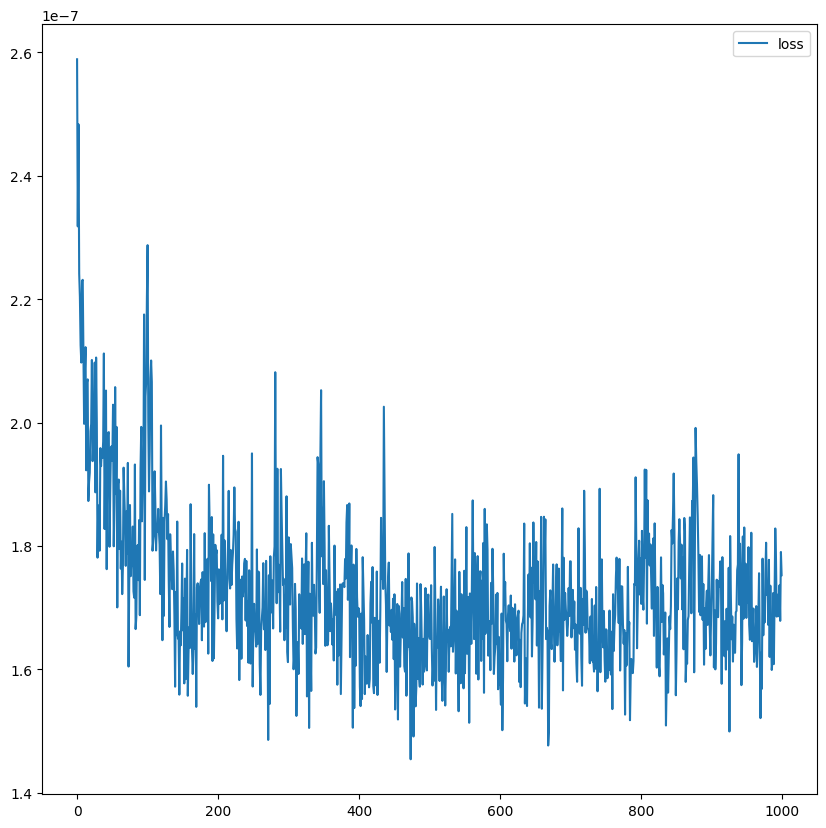

In [ ]:
# Train model
max_iter = 1000
num_samples = 2 ** 12
show_iter = 100


loss_hist = np.array([])

optimizer = torch.optim.AdamW(nfm.parameters(), lr=1e-3, weight_decay=1e-4)
for it in tqdm.tqdm(range(max_iter)):
    optimizer.zero_grad()

    ### Sampling target for cross entropy loss 
    # x = nfm.p.sample(num_samples).double()

    ### Test: Sampling Uniformly for D_KL Loss
    # x, log_probs_q = nfm.sample(num_samples = num_samples)
    x = nfm.q0.sample(num_samples = num_samples)


    ### Loss: Calculating forward KLD using implicit value for p(x) through sampling 
    # loss = nfm.forward_kld(x)

    #loss = -torch.mean(log_probs[~torch.isinf(log_probs)])
    
    ### Test: Calculating D_KL as loss directly
    log_probs_p = nfm.p.log_prob(x)
    probs_p = torch.exp(log_probs_p)
    ### Get this one for free when sampling from model
    log_probs_q = nfm.log_prob(x)
    
    ### Since p is independent of the weights, the following calculation of kl_divs are equivalent 
    ### Given a fixed seed they produce the exact same results
    # kl_divs = probs_q * (log_probs_p - log_probs_q)
    kl_divs = -probs_p * log_probs_q
    loss = torch.mean(kl_divs[~(torch.isnan(kl_divs) | torch.isinf(kl_divs))])

    if ~(torch.isnan(loss) | torch.isinf(loss)):
        loss.backward()
        optimizer.step()
        loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())
    
    # Plot learned distribution
    if (it + 1) % show_iter == 0:
        compare_model(nfm, device, low = 0, high = 1)

plt.figure(figsize=(10, 10))
plt.plot(loss_hist, label='loss')
plt.legend()
plt.show()

# KL Divergence Loss Learnings

- Uniform base distribution works much better than Gaussian 
    - Likely due to better being able to explore the Domain
    - Gaussian learns the center of the domain very vell, but the rest gets ignored
- initIdentity = True -> Very helpful in beginning
- TODO:
    - Test with sampling from the models output itself

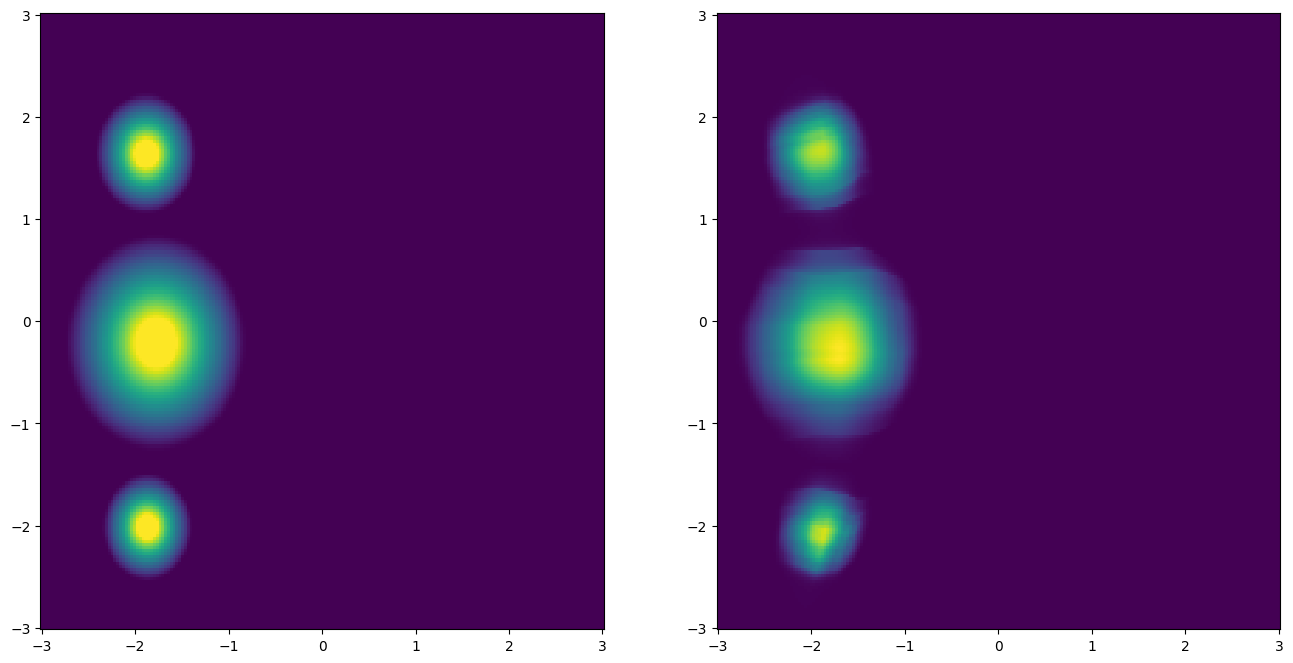

In [56]:
compare_model(nfm, device = device, grid_size=200)

# What now

##### Looking further target

Use InstantNGP for conditioning of the models

##### ToDos Now

- Try out different ways to encode conditioning data
- Read up one InstantNGP
- Probably will need more difficult conditioning tasks
    - Spatial conditioning ?
    - This might require quite a bit of work

# Multi Resolution Hash Encoding Test

In [ ]:
enable_cuda = True
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')
print(torch.cuda.is_available())
print(f"Using device: {device}")


conf = MultiresEncodingConfig()

conf.nlevels = 8
conf.maxres = 2 ** 16
conf.minres = (16, 16)
conf.maxres = (512, 512)

mrhEncoding = MultiresEncoding(**vars(conf), dtype=torch.float64, device = device)


K = 4
torch.manual_seed(0)

use_one_blob = False

### Used for non-encoded
latent_size = 2

# latent_size = 16

hidden_units = 64
hidden_layers = 1

context_size = conf.nlevels * conf.features

mask = np.array([1, 0])

flows = []
for i in range(K):
    # flows += [RealNVPFlow(mask, 64)]
    # mask = 1 - mask
    flows += [nf.flows.AutoregressiveRationalQuadraticSpline(
        latent_size, 
        hidden_layers, 
        hidden_units,
        num_context_channels=context_size, 
        tail_bound = 3.0,
        num_bins = 5,
        init_identity = True,
        permute_mask=True)]
    # flows += [nf.flows.LULinearPermute(latent_size)]


# img = plt.imread('assets/test_distributions/complex.jpg')[:, :, 0] # Specify the path to your image here
img = plt.imread('../assets/test_distributions/Checkerboard.png') # Specify the path to your image here
target = nf.distributions.ImagePrior(img)
target.to(device)
# q0 = nf.distributions.DiagGaussian(2)

low = torch.tensor([-3.0]).type(torch.float64)
high = torch.tensor([3.0]).type(torch.float64)
# q0 = nf.distributions.base.Uniform(2, low = low, high = high)
q0 = Uniform(2, low = low, high = high, device = device)

# q0.low = q0.low.to(device)
# q0.high = q0.high.to(device)
# q0.log_prob_val = q0.log_prob_val.to(device)

nfm = nf.ConditionalNormalizingFlow(q0=q0, flows=flows, p=target)
nfm = nfm.double()
nfm = nfm.to(device)

True
Using device: cuda


 50%|████▉     | 999/2000 [01:58<01:57,  8.50it/s]

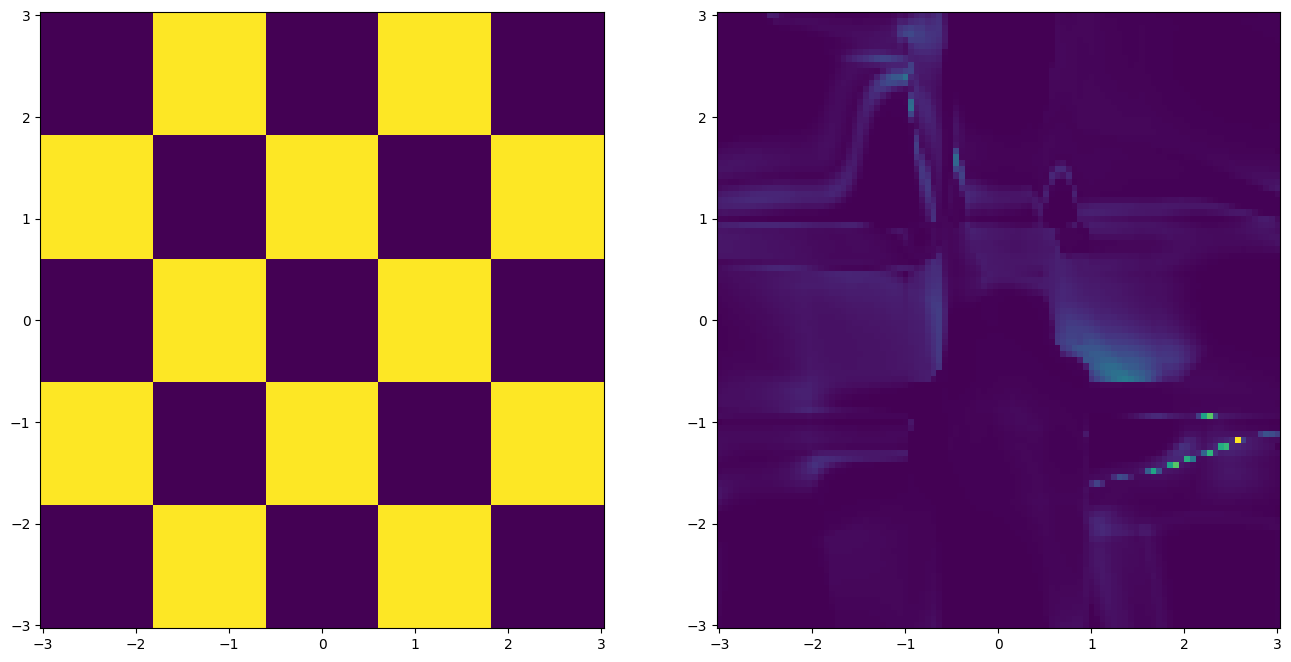

100%|█████████▉| 1999/2000 [03:55<00:00,  8.50it/s]

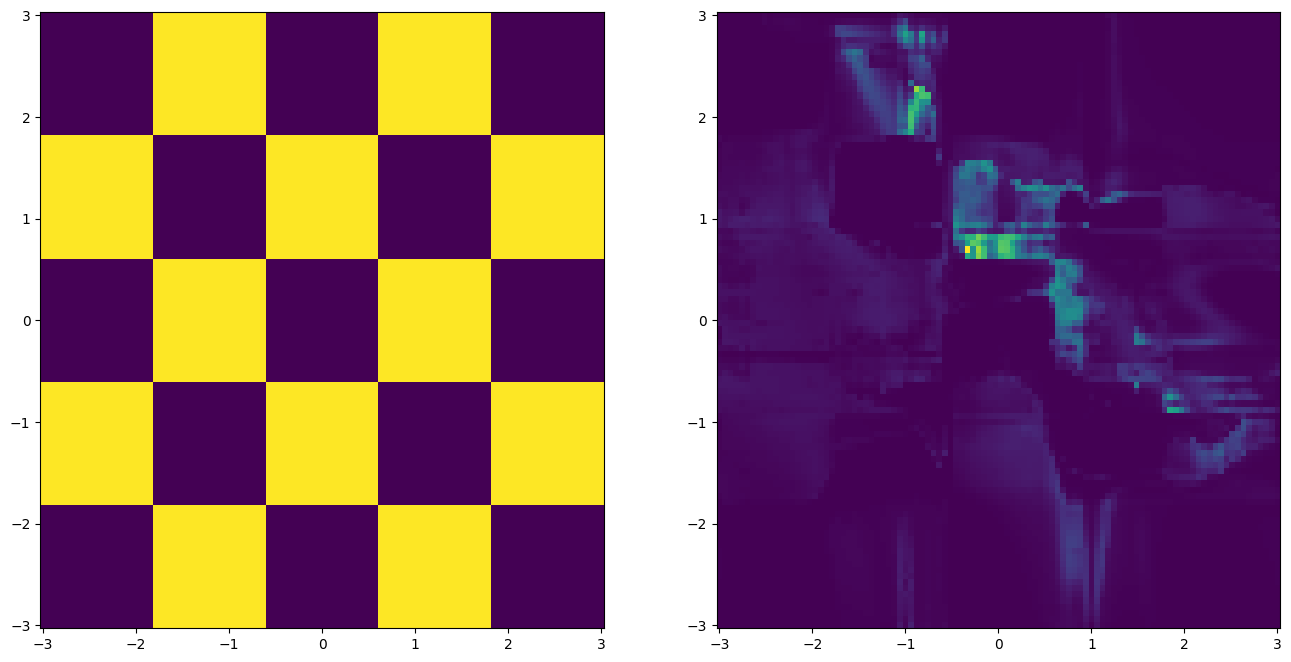

100%|██████████| 2000/2000 [03:55<00:00,  8.48it/s]


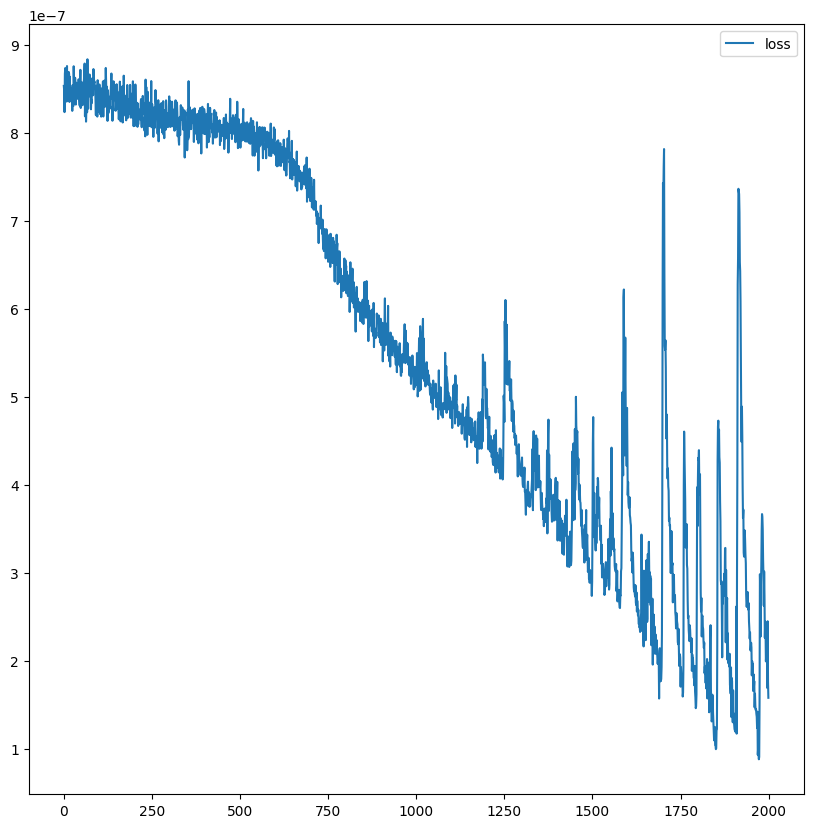

In [7]:
### Train model
max_iter = 2000
num_samples = 2 ** 12
show_iter = 1000

loss_hist = np.array([])

### This is without encoder/decoder
p = list(nfm.parameters()) + list(mrhEncoding.parameters())
optimizer = torch.optim.AdamW(p, lr=1e-3, weight_decay=1e-2)

import time

times = [[], [], [], [], []]
sampling_index = 0
encoding_index = 1
base_dist_index = 2
eval_index = 3
train_index = 3

last_time = time.time()

for it in tqdm.tqdm(range(max_iter)):
    optimizer.zero_grad()

    # normals = normal.expand((num_samples, 3))

    """ ----- Sampling ----- """

    ### Sampling target for cross entropy loss 
    # x = nfm.p.sample(num_samples = num_samples, normals = normals).to(device).double()

    ### Test: Sampling Uniformly for D_KL Loss

    last_time = time.time()
    x = nfm.q0.sample(num_samples = num_samples).type(torch.float64)

    times[sampling_index].append(time.time() - last_time)
    last_time = time.time()

    ### Do I have some sort of GPU memory leak here ???
    mr_grid_features = mrhEncoding(x)

    times[encoding_index].append(time.time() - last_time)
    last_time = time.time()

    
    """ ----- Loss Calculation -----"""
    log_probs_p = nfm.p.log_prob(x)

    times[base_dist_index].append(time.time() - last_time)
    last_time = time.time()

    probs_p = torch.exp(log_probs_p)
    last_time = time.time()
    ### Get this one for free when sampling from model
    log_probs_q = nfm.log_prob(x, context = mr_grid_features)

    times[eval_index].append(time.time() - last_time)
    last_time = time.time()
    
    # kl_divs = -probs_q * log_probs_p ## reverse KLD ?

    
    kl_divs = -probs_p * log_probs_q # KLD


    loss = torch.mean(kl_divs[~(torch.isnan(kl_divs) | torch.isinf(kl_divs))])


    if ~(torch.isnan(loss) | torch.isinf(loss)):
        last_time = time.time()
        loss.backward()
        optimizer.step()
        loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())

        times[train_index].append(time.time() - last_time)
        last_time = time.time()
    
    # Plot learned distribution
    if (it + 1) % show_iter == 0:
        compare_model_context(nfm, device, mrhEncoding)

plt.figure(figsize=(10, 10))
plt.plot(loss_hist, label='loss')
plt.legend()
plt.show()

In [ ]:
mean_sampling = np.array(times[sampling_index]).mean()
mean_encoding = np.array(times[encoding_index]).mean()
mean_basedist = np.array(times[base_dist_index]).mean()
mean_inference = np.array(times[eval_index]).mean()
mean_backward = np.array(times[train_index]).mean()

print(f"sampling mean: {mean_sampling}")
print(f"encoding mean: {mean_encoding}")
print(f"basedist mean: {mean_basedist}")
print(f"inference mean: {mean_inference}")
print(f"backward mean: {mean_backward}")

sampling mean: 0.000194277286529541
encoding mean: 0.003559114933013916
basedist mean: 0.00018107223510742187
inference mean: 0.10770833063125611
backward mean: 0.10770833063125611


##### 1000 its - 2^10 batch size

sampling mean: 0.00019993066787719728
encoding mean: 0.003795423984527588
basedist mean: 0.00019219636917114258
inference mean: 0.06800934958457946
backward mean: 0.11483692789077758

##### 1000 its - 2^12 batch size

sampling mean: 0.00020922636985778808
encoding mean: 0.0038395395278930664
basedist mean: 0.00018886756896972656
inference mean: 0.08019895434379577
backward mean: 0.1473966724872589

##### ~125 its before stopping - 2^16 batch size

sampling mean: 0.00025636998433915397
encoding mean: 0.00463598682766869
basedist mean: 0.00025860279325454953
inference mean: 2.634247039794922
backward mean: 1.9882023525238037

In [51]:
# Class taken and adapted from the source code of https://github.com/VincentStimper/normalizing-flows
class ImagePrior(torch.nn.Module):
    """
    Intensities of an image determine probability density of prior
    """

    def __init__(self, 
                 image, 
                 domain = [[0, 1], [0, 1]], 
                 eps=1.0e-10, 
                 dtype=torch.float32, 
                 add_flat_gaussian: bool = True, 
                 normalize = True):
        """Constructor

        Args:
          image: image as np matrix
          index_0_1: Whether to index from [0, 1]^2 instead of [-1, 1]^2
          eps: small value to add to image to avoid log(0) problems
        """
        super().__init__()

        if add_flat_gaussian:
            xx, yy = torch.meshgrid(torch.linspace(-1, 1, image.shape[0]), torch.linspace(-1, 1, image.shape[1]))
            zz = torch.cat([xx.unsqueeze(2), yy.unsqueeze(2)], 2).view(-1, 2)

            sigma = 10
            dist = torch.distributions.multivariate_normal.MultivariateNormal(torch.zeros(2), torch.eye(2) * sigma)

            log_probs = dist.log_prob(zz).view(*xx.shape)
            probs = torch.exp(log_probs)

            image_tens = torch.tensor(image, dtype=dtype) + probs
        else:
            image_tens = torch.tensor(image, dtype=dtype)

        if normalize:
            image_ = (image_tens / image_tens.sum() + eps)[None, None, ..., ...]
        else:
            image_ = image_tens[None, None, ..., ...]
        self.image_dims = image_.shape
        
        self.register_buffer("domain", torch.as_tensor(domain))
        self.register_buffer("log_eps", torch.log(torch.tensor(eps, dtype=dtype)))
        self.register_buffer(
            "density", image_ / torch.sum(image_)
        )

    def from_domain(self, x):
        x = (x - self.domain[:, 0]) / (self.domain[:, 1] - self.domain[:, 0])
        return x * 2 - 1
    
    def to_domain(self, x):
        x = (x + 1) / 2
        return x * (self.domain[:, 1] - self.domain[:, 0])
        

    def log_prob(self, z):
        """
        Args:
          z: value or batch of latent variable

        Returns:
          log probability of the distribution for z
        """

        # Map into [-1, 1] when user wants to index in [0, 1]
        z = self.from_domain(z)

        z = z[None, None, ..., ...]

        log_probs = torch.log(torch.nn.functional.grid_sample(self.density, z, mode='bilinear').view(-1))

        return torch.where(torch.isinf(log_probs), self.log_eps, log_probs)
    
    def prob(self, z):
        """
        Args:
          z: value or batch of latent variable

        Returns:
          probability of the distribution for z
        """

        # Map into [-1, 1] when user wants to index in [0, 1]
        z = self.from_domain(z)

        z = z[None, None, ..., ...]

        return torch.nn.functional.grid_sample(self.density, z).view(-1)

In [52]:
import models
import priors
importlib.reload(models)
importlib.reload(priors)
import models
import priors

# TODO: Add way to specifiy feature count
def get_default_encoding(device):
    conf = MultiresEncodingConfig()

    conf.nlevels = 8
    conf.minres = (16, 16)
    conf.maxres = (512, 512)

    return MultiresEncoding(**vars(conf), dtype=torch.float32, device = device)

def get_default_prior(means, stds):
    return priors.DiagGaussianPrior(means, stds)

def get_default_target(domain, normalize = False):
    # img = plt.imread('../assets/test_distributions/museum.jpg').sum(axis=-1)
    img = plt.imread('../assets/test_distributions/TestDist2.png').sum(axis=-1)
    return ImagePrior(img, domain = domain, add_flat_gaussian=False, normalize=normalize)


using device: cuda


C:\Users\janlu\AppData\Local\Temp\ipykernel_8420\4193100859.py:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


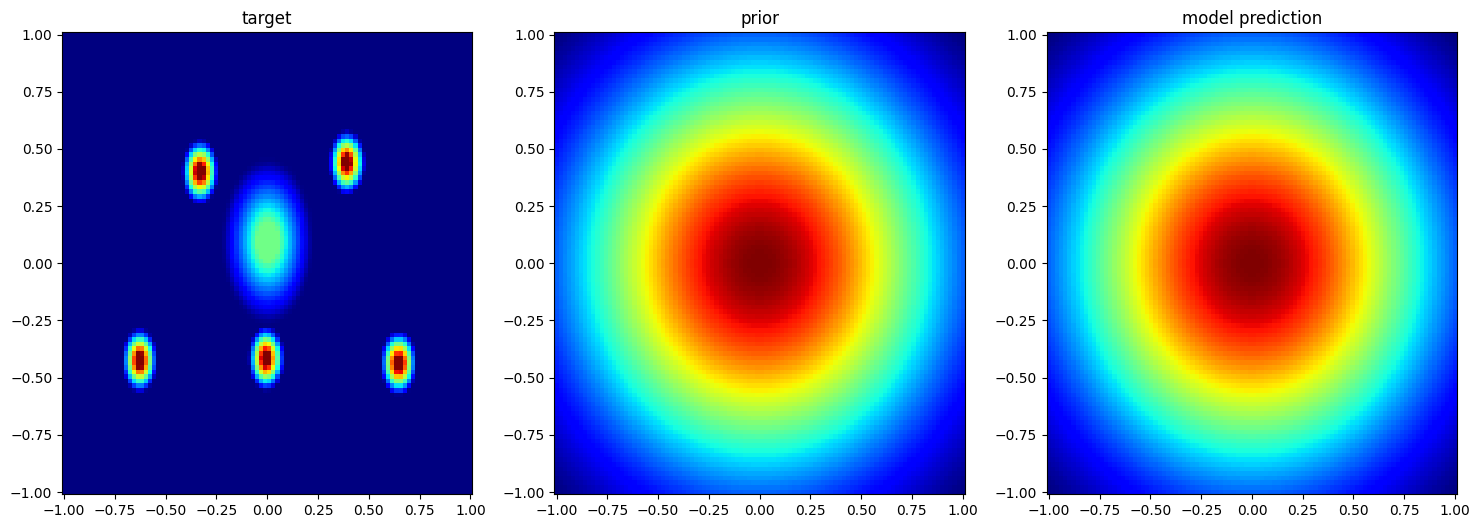

In [71]:
enable_cuda = True
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')

K = 8

hidden_units = 16
hidden_layers = 1

latent_size = 2

# domain = torch.as_tensor([[0, torch.pi * 2], [0, torch.pi]])
domain = torch.as_tensor([[-1, 1], [-1, 1]])
means = (domain[:, 1] + domain[:, 0]) / 2
stds = (domain[:, 1] - domain[:, 0]) / (torch.pi)

prior = get_default_prior(means, stds)
encoding = get_default_encoding(device)

flows = []
for i in range(K):
    # flows += [RealNVPFlow(mask, 64)]
    # mask = 1 - mask
    flows += [nf.flows.AutoregressiveRationalQuadraticSpline(
        latent_size, 
        hidden_layers, 
        hidden_units,
        num_context_channels=encoding.encoding_size, 
        tail_bound = 3.0,
        num_bins = 8,
        init_identity = True,
        permute_mask=True)]


model: models.AbstractModel = models.NormalizingFlowModel(latent_size, prior, encoding, flows, domain=domain)
target = get_default_target(domain = domain)


model.to(device)
target.to(device)
print(f"using device: {device}")

fig = model.visualize(target)
fig.show()

  0%|          | 0/1000 [00:00<?, ?it/s]

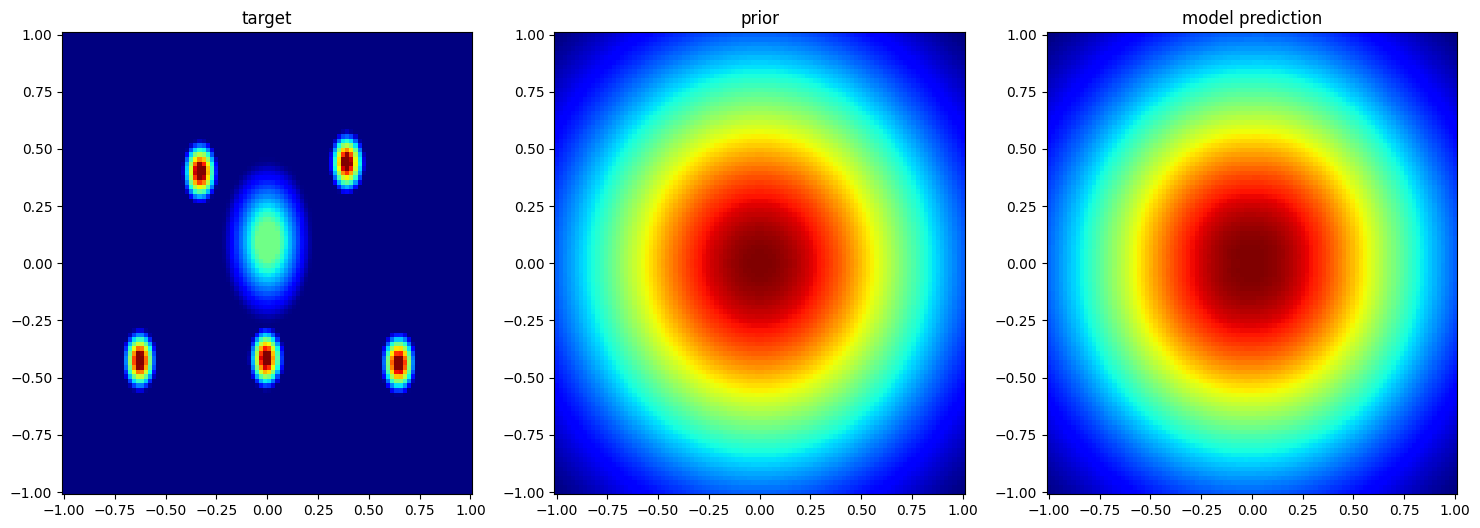

 10%|█         | 100/1000 [00:19<02:57,  5.07it/s]

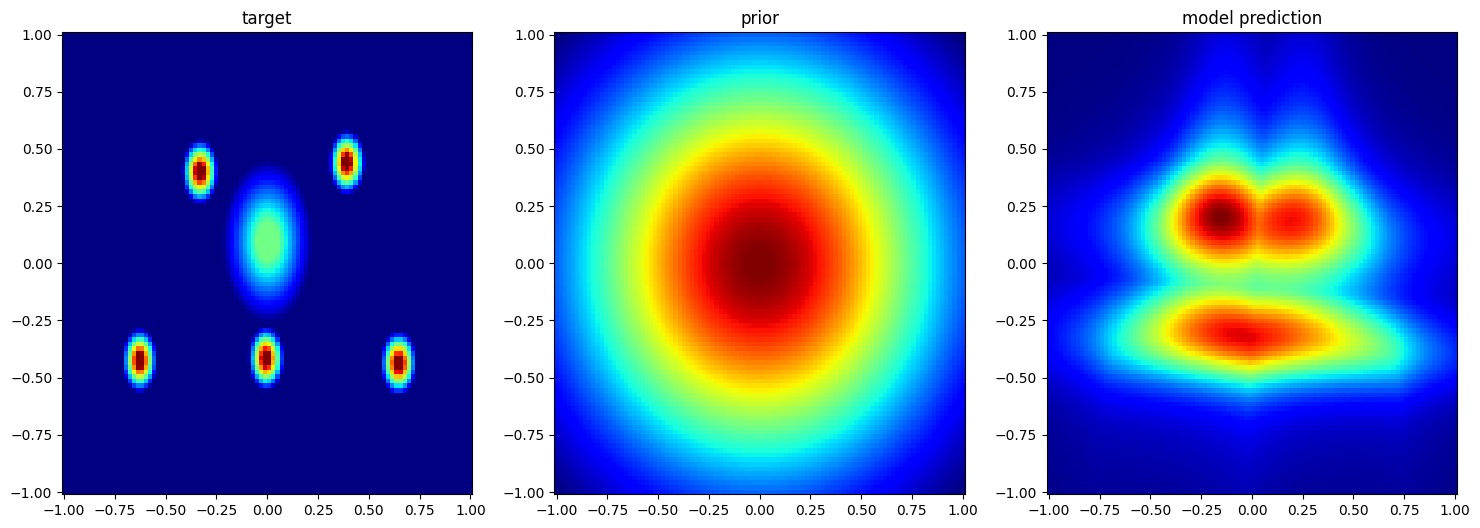

 20%|██        | 200/1000 [00:38<02:23,  5.58it/s]

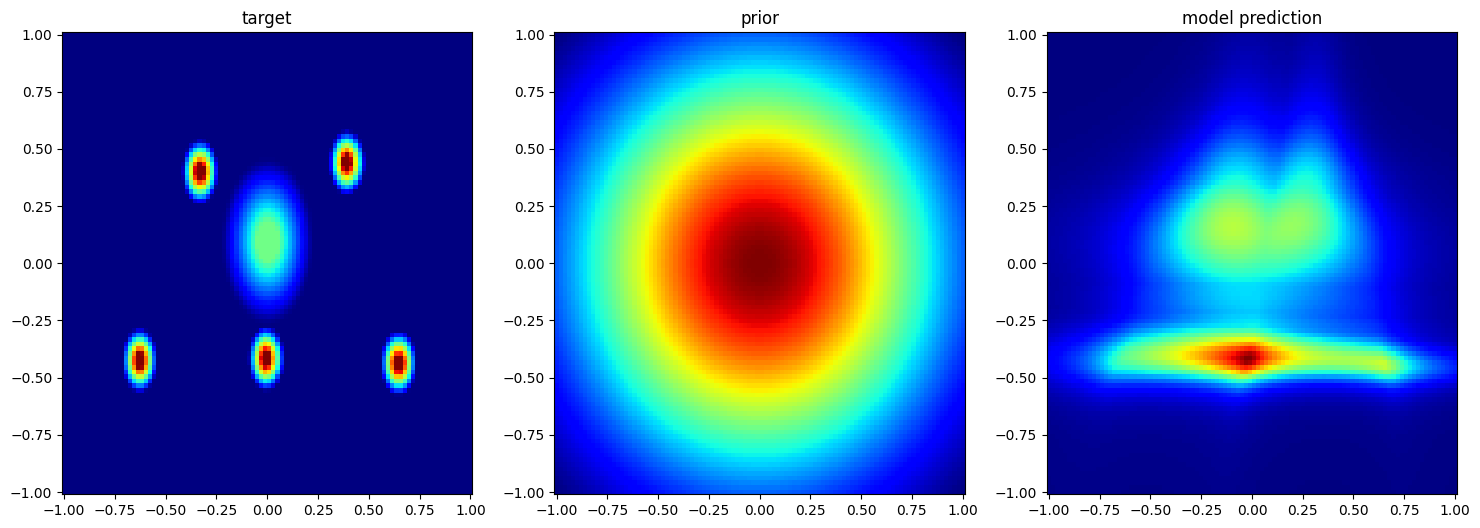

 30%|███       | 300/1000 [00:57<02:09,  5.41it/s]

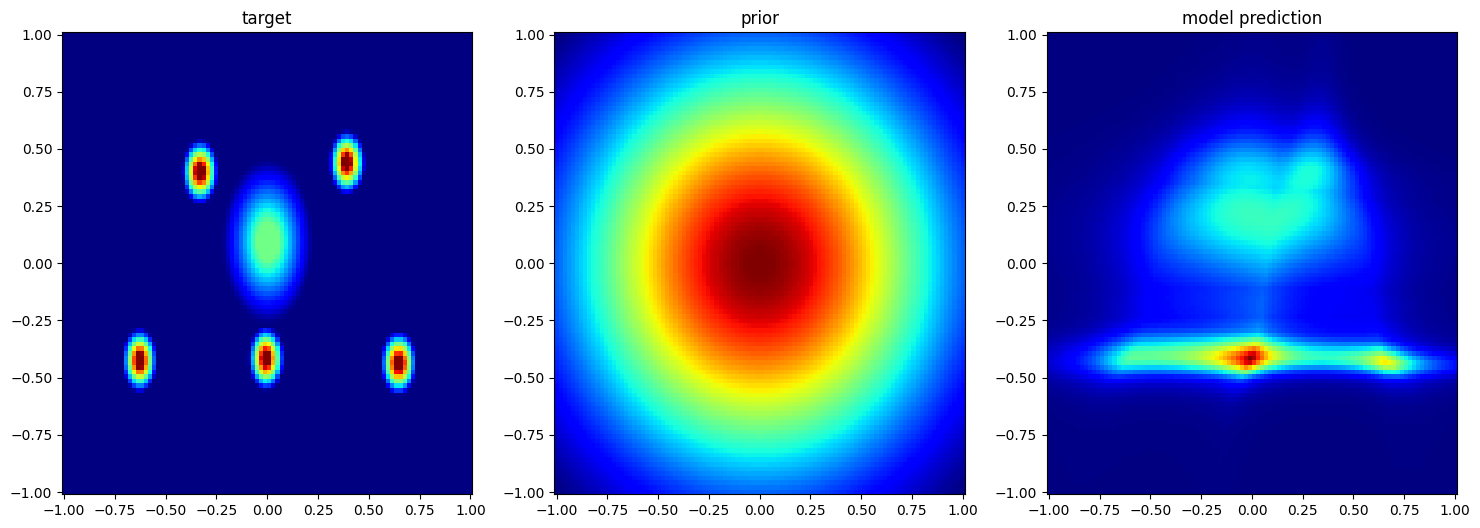

 40%|████      | 400/1000 [01:16<01:49,  5.47it/s]

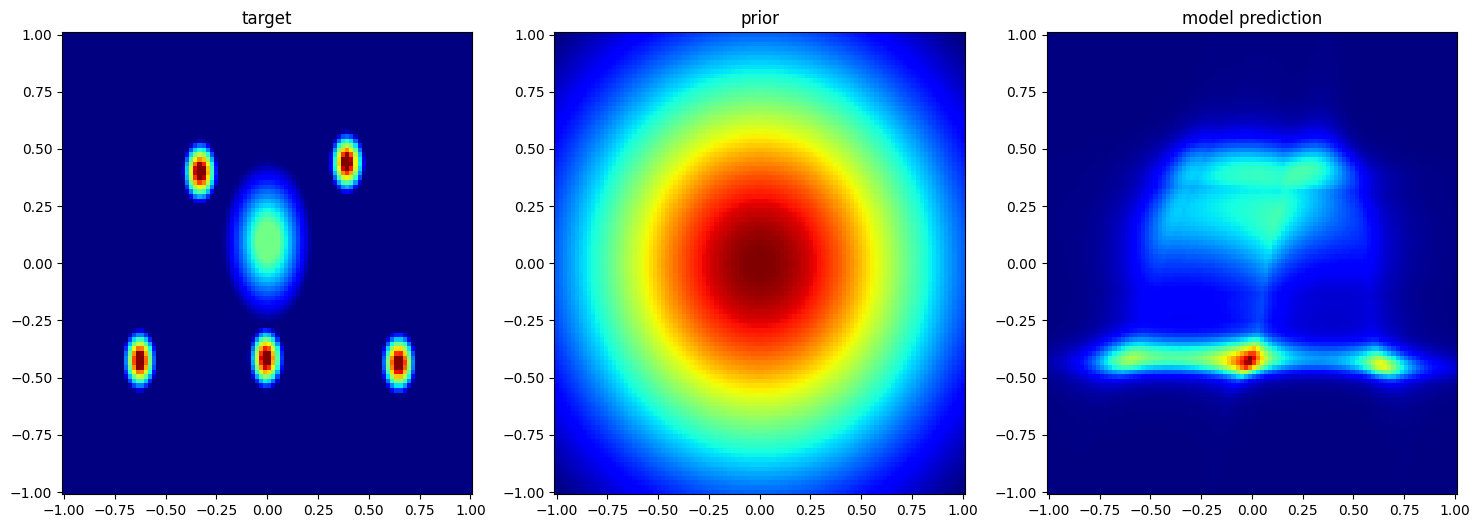

 50%|█████     | 500/1000 [01:34<01:30,  5.51it/s]

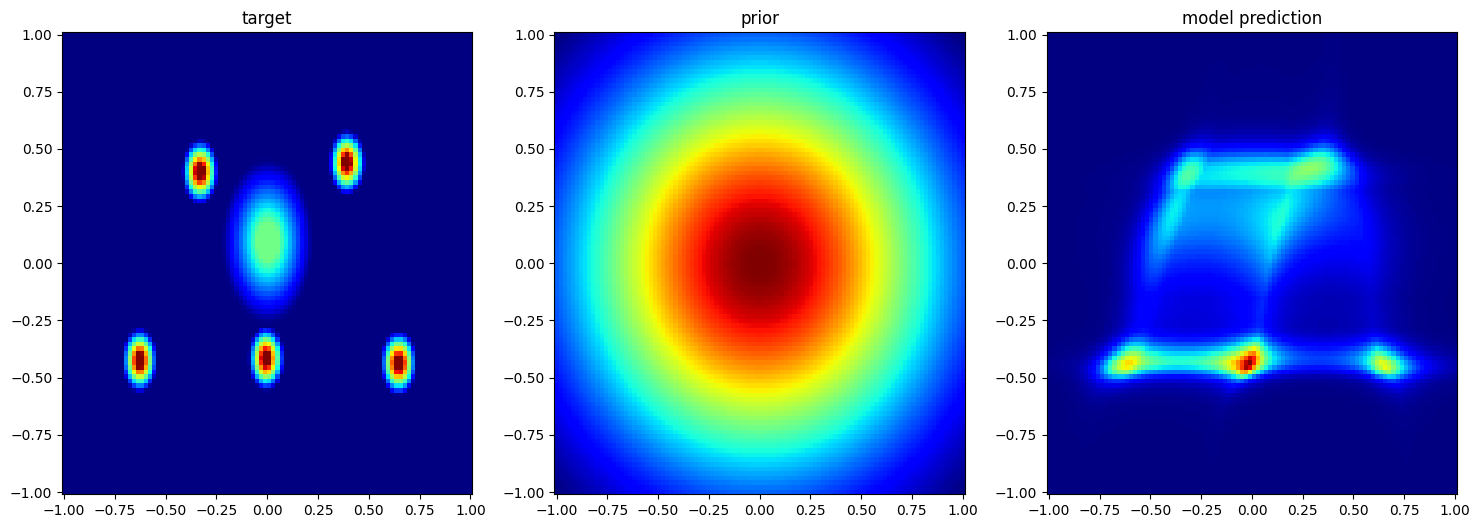

 60%|██████    | 600/1000 [01:53<01:14,  5.38it/s]

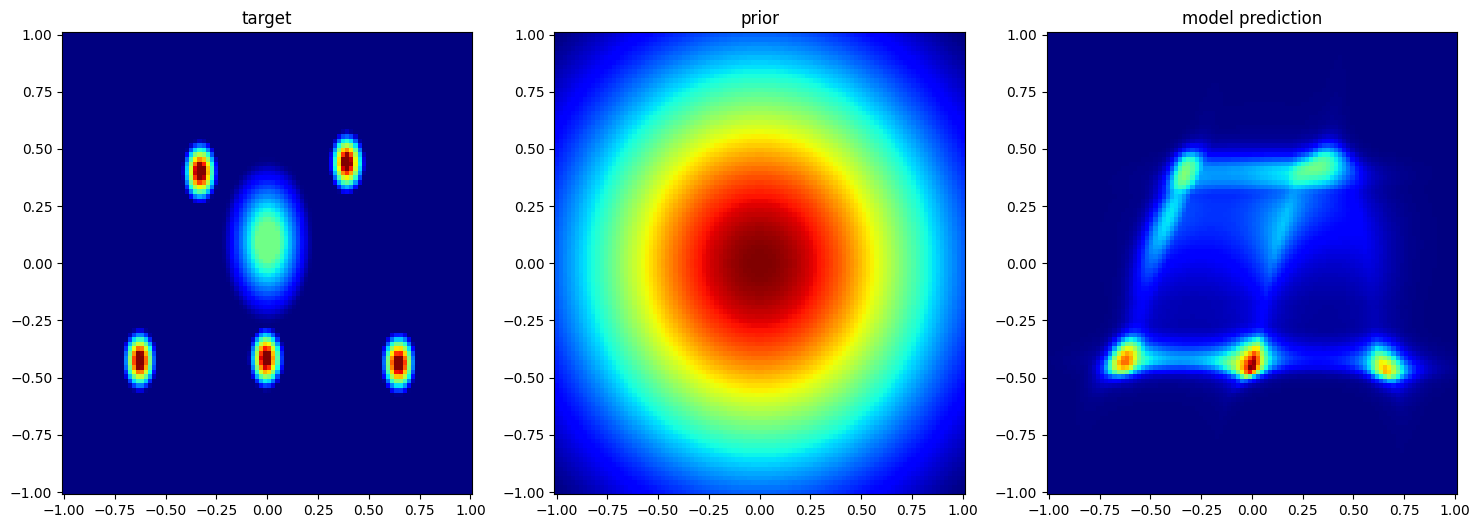

 70%|███████   | 700/1000 [02:12<00:55,  5.45it/s]

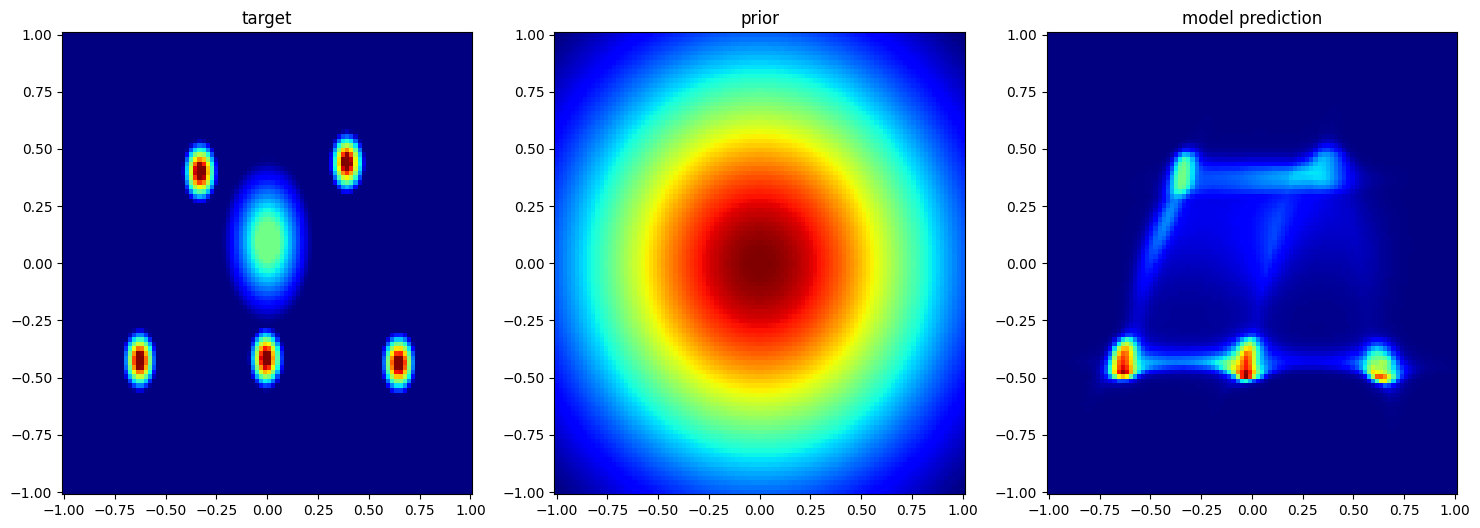

 80%|████████  | 800/1000 [02:31<00:36,  5.55it/s]

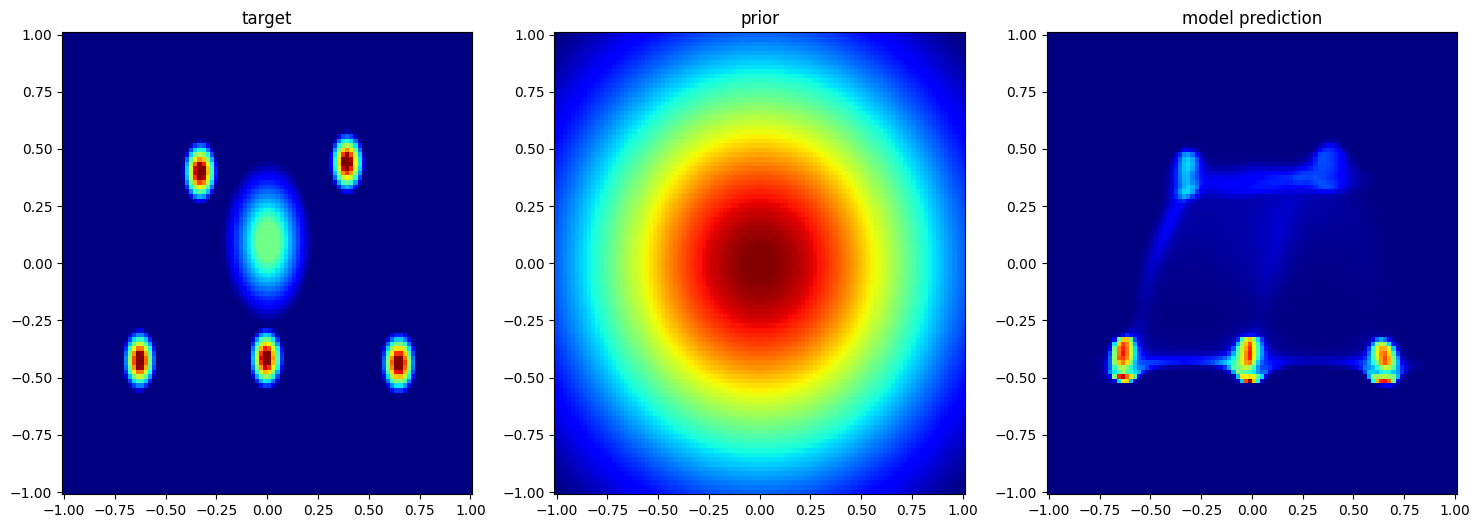

 90%|█████████ | 900/1000 [02:50<00:18,  5.40it/s]

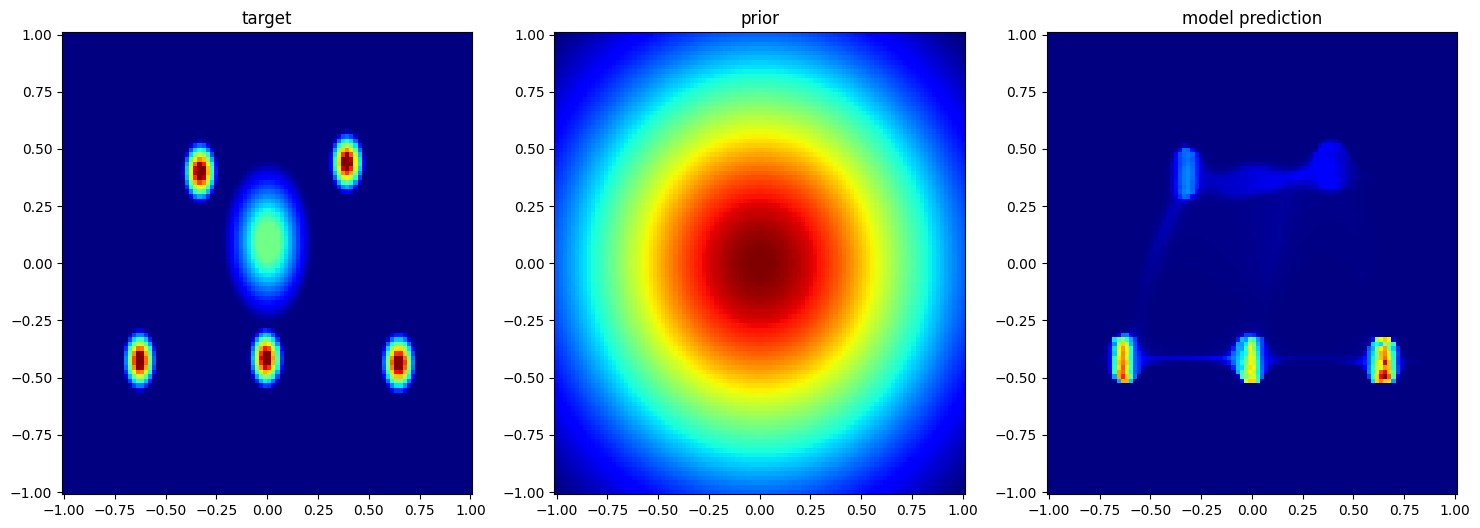

100%|██████████| 1000/1000 [03:09<00:00,  5.27it/s]


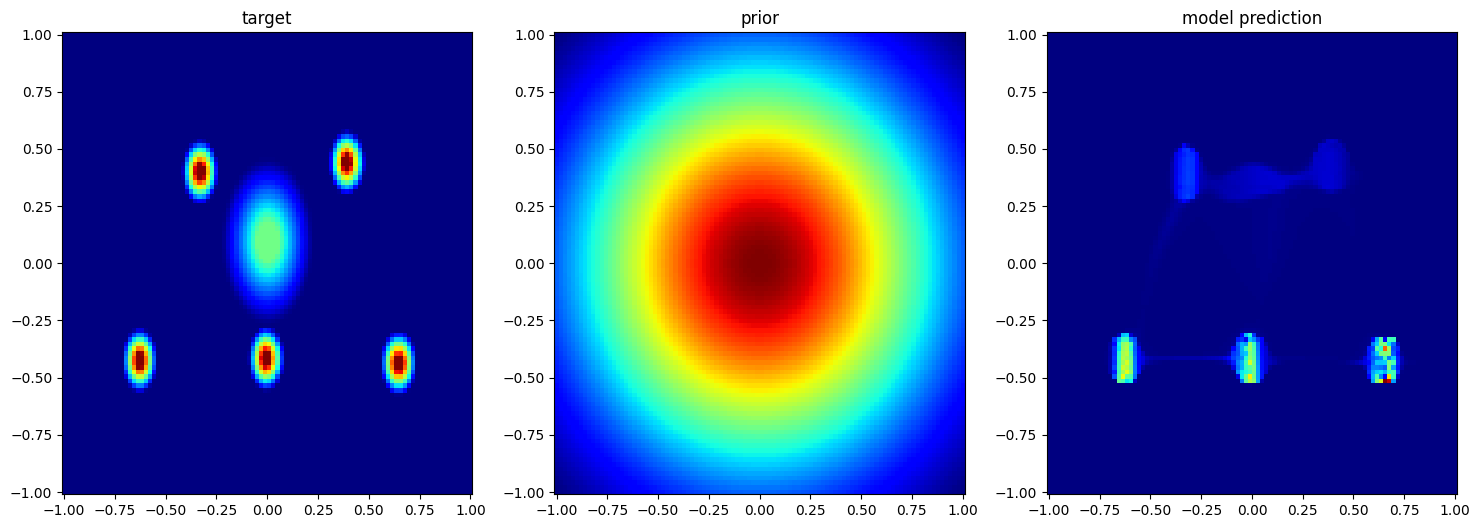

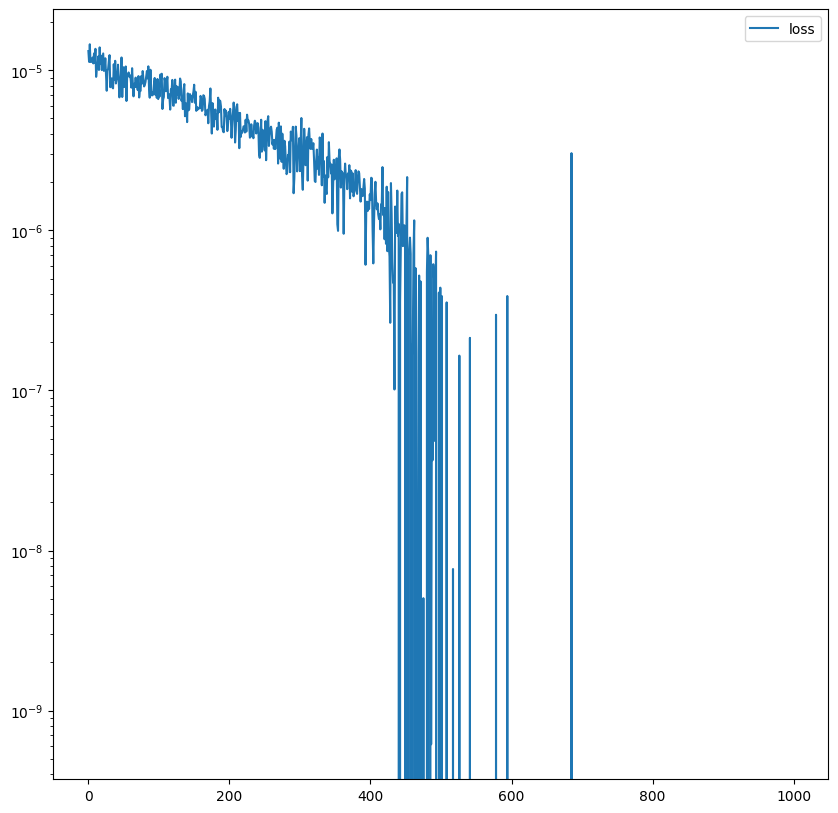

In [72]:
# Train model

iterations = 1000
num_samples = 2 ** 10

num_training_plots = 10
plot_every = int(iterations / num_training_plots if num_training_plots > 0 else iterations + 1)

loss_hist = np.array([])


clip_grad = True
clip_max_norm = 0.5


optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-3)


iterator = tqdm.tqdm(range(iterations))
for it in iterator:
    optimizer.zero_grad()

    # batch = torch.rand((num_samples, 2), device = device) * 2 - 1
    # batch, batch_pdf = model.sample(num_samples)
    # batch_pdf = batch_pdf.exp()

    batch = model.prior.sample(num_samples)
    batch_pdf = model.prior.log_prob(batch).exp()

    loss = model.compute_batch_gradient(target, batch, probs_q, batch_pdf)

    for p in model.parameters():
        p.grad = torch.nan_to_num(p.grad)

    loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())


    if clip_grad:
        ### Network and Encoding clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=clip_max_norm)

    optimizer.step()
        
    
    if (it != 0 or plot_every < iterations) and it % plot_every == 0: 
        fig = model.visualize(target)
        plt.show()


fig = model.visualize(target)
plt.show()

plt.figure(figsize=(10, 10))
plt.semilogy(loss_hist, label='loss')
plt.legend()
plt.show()

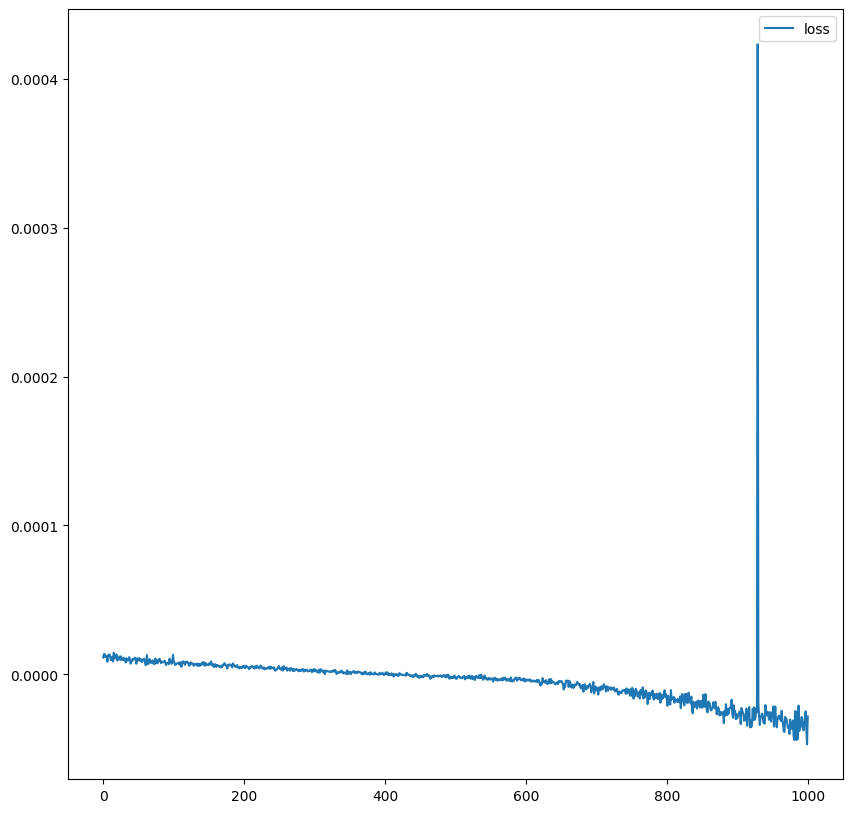

In [70]:
plt.figure(figsize=(10, 10))
plt.plot(loss_hist, label='loss')
plt.legend()
plt.show()

# Multiresolution Hash Encoding with directional conditioning

In [ ]:
enable_cuda = True
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')
print(f"Using device: {device}")

data_type = torch.float32
print(f"Using datatype: {data_type}")

### --------------------- ###

conf = MultiresEncodingConfig()

conf.nlevels = 2
conf.maxres = 2 ** 16
conf.minres = (16, 16)
conf.maxres = (512, 512)

mrhEncoding = MultiresEncoding(**vars(conf), dtype=data_type, device = device)

### --------------------- ###

conf_normal = MultiresEncodingConfig()

conf_normal
conf_normal.nlevels = 6
conf_normal.maxres = 2 ** 16
conf_normal.minres = (16, 16, 16)
conf_normal.maxres = (128, 128, 128)

mrhEncoding_normal = MultiresEncoding(**vars(conf_normal), dtype=data_type, device = device)



### --------------------- ###

K = 4
# torch.manual_seed(0)

latent_size = 2
hidden_units = 64
hidden_layers = 2

dir_encoding_size = conf.nlevels * conf.features
# normal_encoding_size = conf_normal.nlevels * conf_normal.features
normal_encoding_size = 3

context_size = normal_encoding_size + dir_encoding_size

mask = np.array([1, 0])

flows = []
for i in range(K):
    # flows += [RealNVPFlow(mask, 64)]
    # mask = 1 - mask
    flows += [nf.flows.AutoregressiveRationalQuadraticSpline(
        latent_size, 
        hidden_layers, 
        hidden_units,
        num_context_channels=context_size, 
        permute_mask=True)]
    # flows += [nf.flows.LULinearPermute(latent_size)]


### --------------------- ###


# img = plt.imread('assets/test_distributions/complex.jpg')[:, :, 0] # Specify the path to your image here
img = plt.imread('assets/test_distributions/Checkerboard.png') # Specify the path to your image here
# target = nf.distributions.ImagePrior(img)
target = LambertConditionedImagePrior(img)
target.to(device)
# q0 = nf.distributions.DiagGaussian(2)

low = torch.tensor([-3.0]).type(data_type)
high = torch.tensor([3.0]).type(data_type)
q0 = Uniform(2, low = low, high = high, device = device)

# q0.low = q0.low.to(device)
# q0.high = q0.high.to(device)
# q0.log_prob_val = q0.log_prob_val.to(device)

nfm = nf.ConditionalNormalizingFlow(q0=q0, flows=flows, p=target)
nfm = nfm.float()
nfm = nfm.to(device)

Using device: cuda
Using datatype: torch.float32


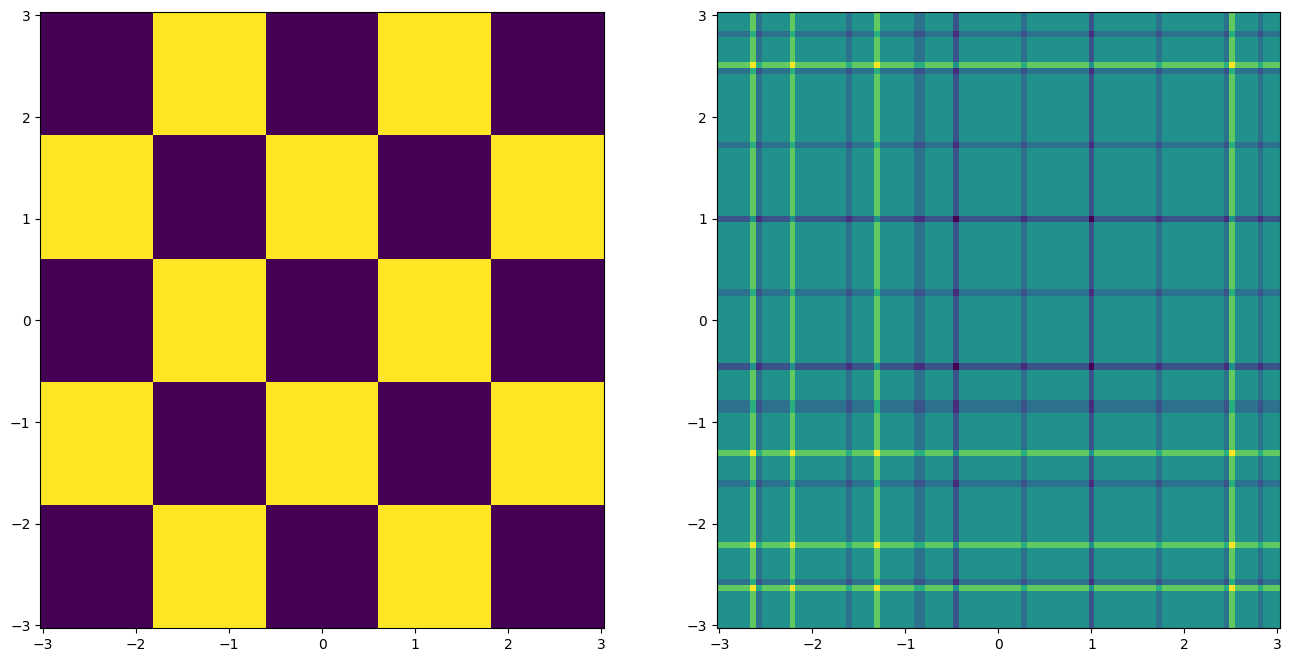

 50%|████▉     | 499/1000 [01:46<01:57,  4.28it/s]

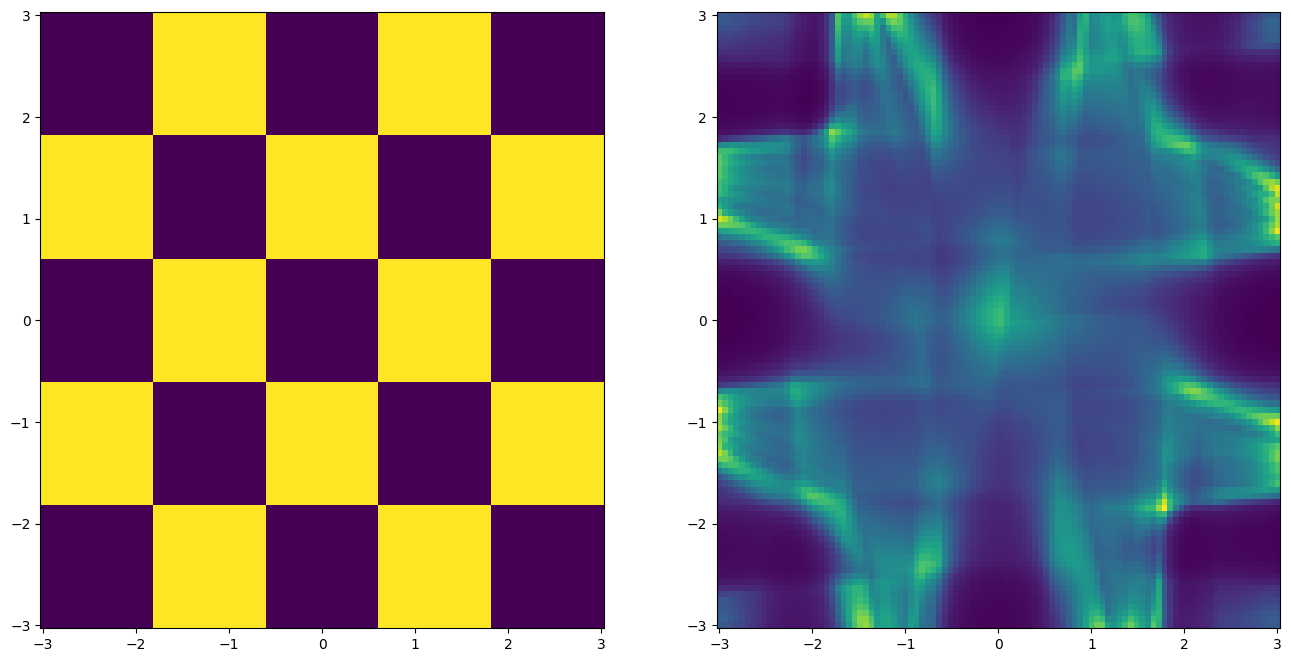

100%|█████████▉| 999/1000 [03:33<00:00,  4.66it/s]

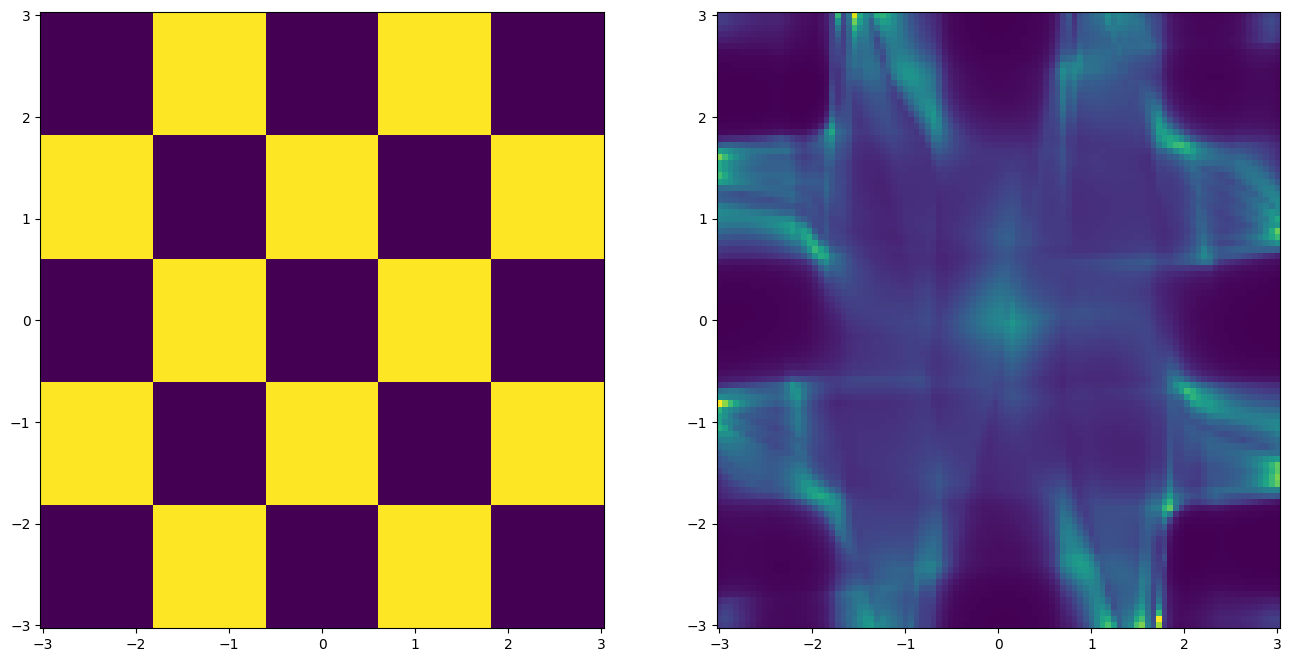

100%|██████████| 1000/1000 [03:33<00:00,  4.68it/s]


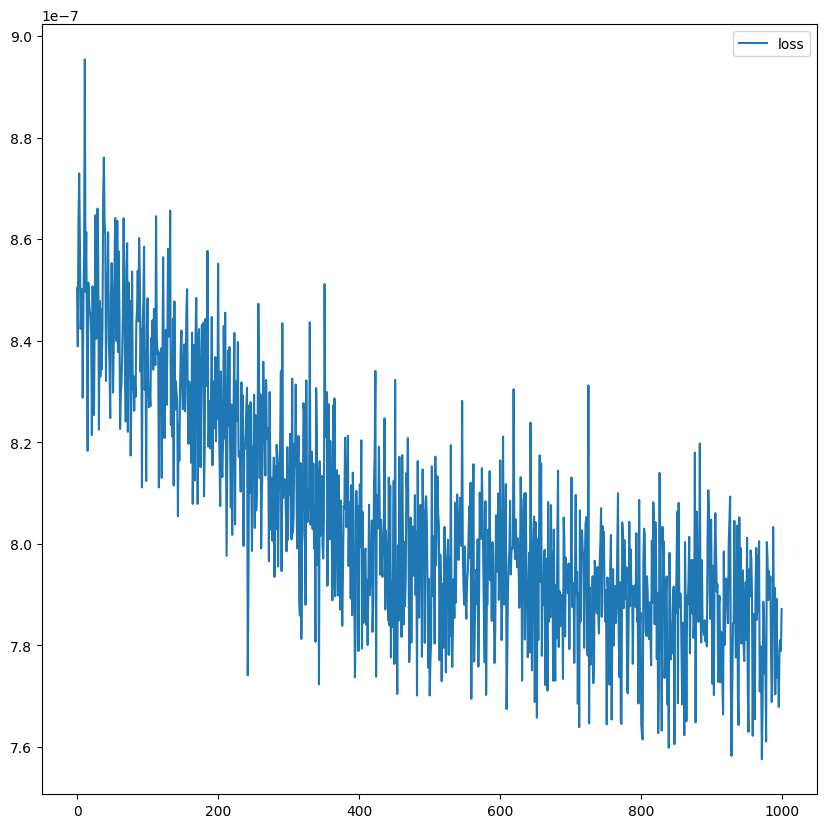

In [ ]:
### Idea: Pre train with completely zero'ed normal vector
# Then train the actualy model

# Train model
max_iter = 4000
num_samples = 2 ** 12
show_iter = 100


loss_hist = np.array([])

normal = torch.tensor([0, 0, 0]).to(device)
compare_model_context_normal(nfm, device, normal = None, mrhEncoding = mrhEncoding)

### This is without encoder/decoder
optimizer = torch.optim.AdamW(nfm.parameters(), lr=1e-4, weight_decay=1e-2)

for it in tqdm.tqdm(range(max_iter)):
    optimizer.zero_grad()


    """ ----- Sampling ----- """

    ### Sampling target for cross entropy loss 
    # x = nfm.p.sample(num_samples = num_samples, normals = normals).to(device).double()

    ### Test: Sampling Uniformly for D_KL Loss
    x = nfm.q0.sample(num_samples = num_samples).type(data_type)
    mr_grid_features = mrhEncoding(x)

    normals = normal.expand((*x.shape[: -1], ) + (normal.shape[0], ))

    model_input = torch.cat((normals, mr_grid_features), dim = 1)

    """ ----- Loss Calculation -----"""
    ### Test: Calculating D_KL as loss directly
    log_probs_p = nfm.p.log_prob(x)
    probs_q = torch.exp(log_probs_p)
    log_probs_q = nfm.log_prob(x, context = model_input)
    
    kl_divs = -probs_q * log_probs_q
    loss = torch.mean(kl_divs[~(torch.isnan(kl_divs) | torch.isinf(kl_divs))])


    if ~(torch.isnan(loss) | torch.isinf(loss)):
        loss.backward()
        optimizer.step()
        loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())
    

    # Plot learned distribution
    if (it + 1) % show_iter == 0:
        # compare_model_context_normal_enc(nfm, device, normal, mrhEncoding_normal, mrhEncoding)
        compare_model_context_normal(nfm, device, normal = None, mrhEncoding = mrhEncoding)

plt.figure(figsize=(10, 10))
plt.plot(loss_hist, label='loss')
plt.legend()
plt.show()

 20%|█▉        | 999/5000 [03:18<13:19,  5.01it/s]

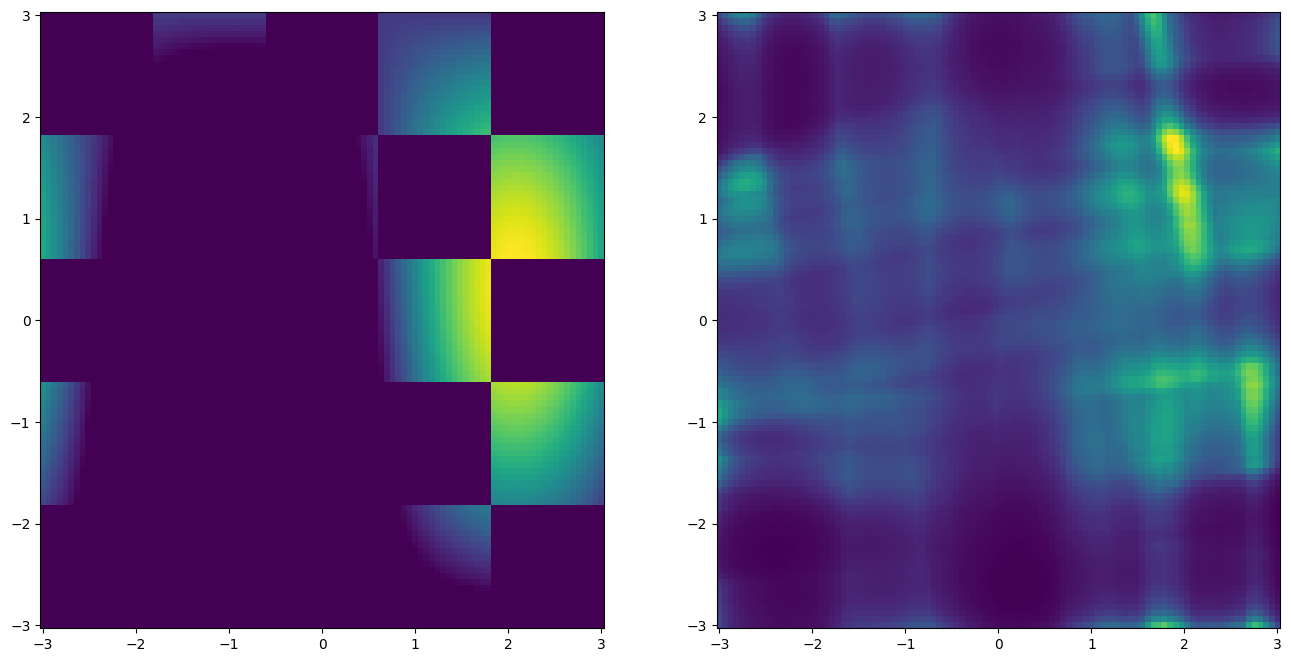

 40%|███▉      | 1999/5000 [06:40<10:01,  4.99it/s]

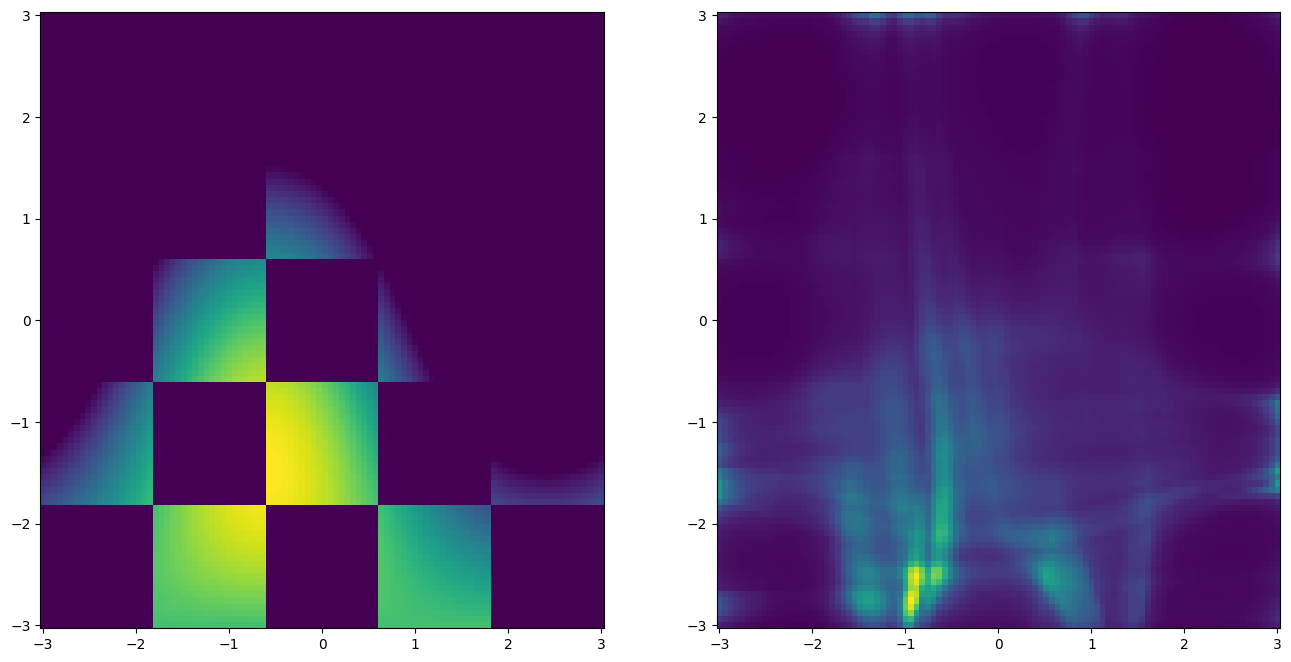

 60%|█████▉    | 2999/5000 [10:03<06:37,  5.04it/s]

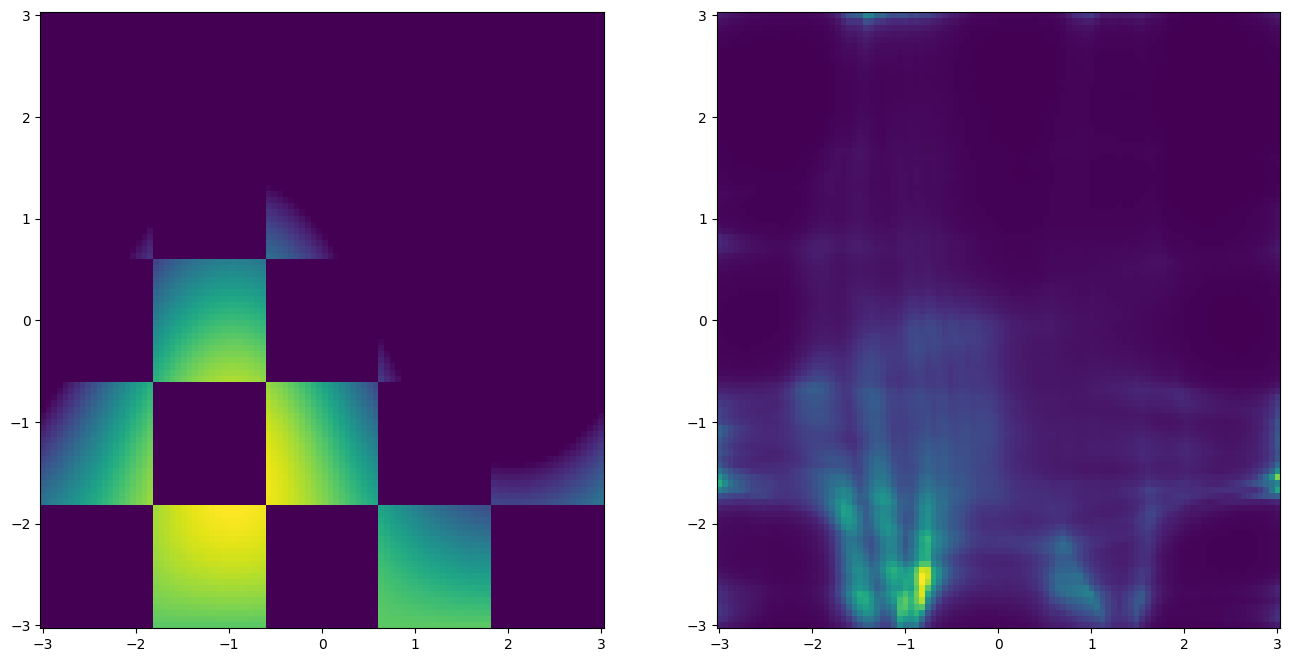

 80%|███████▉  | 3999/5000 [13:26<03:30,  4.75it/s]

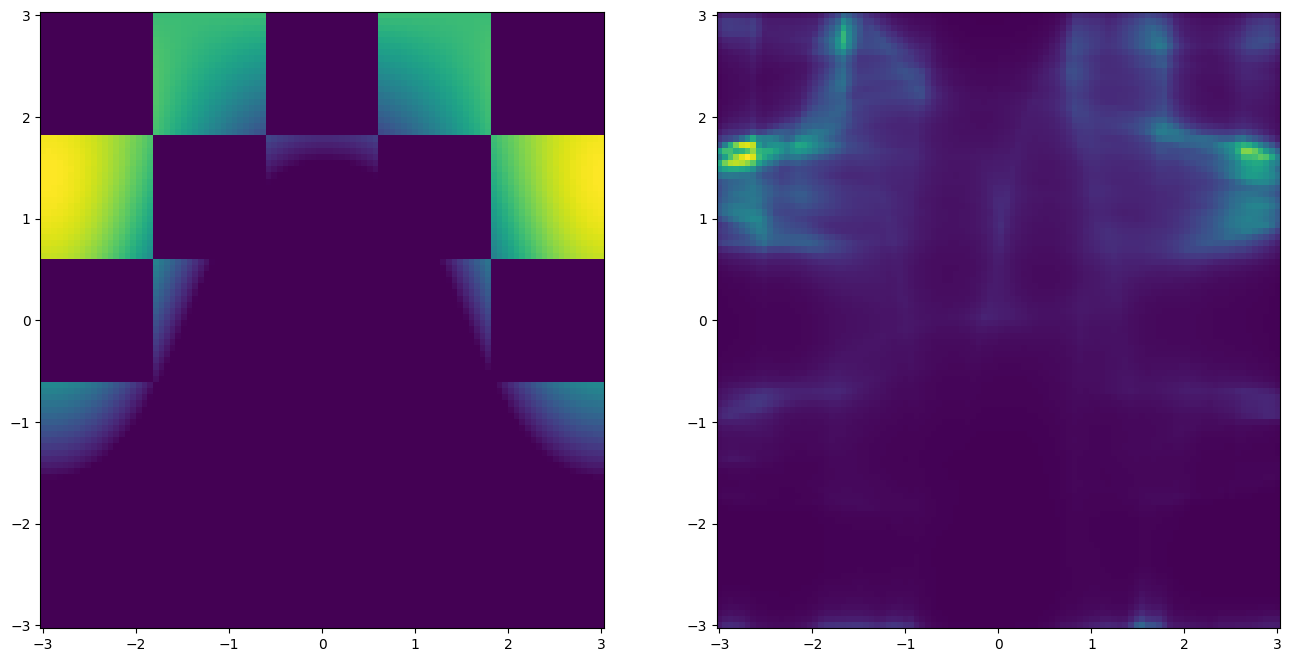

100%|█████████▉| 4999/5000 [16:50<00:00,  4.93it/s]

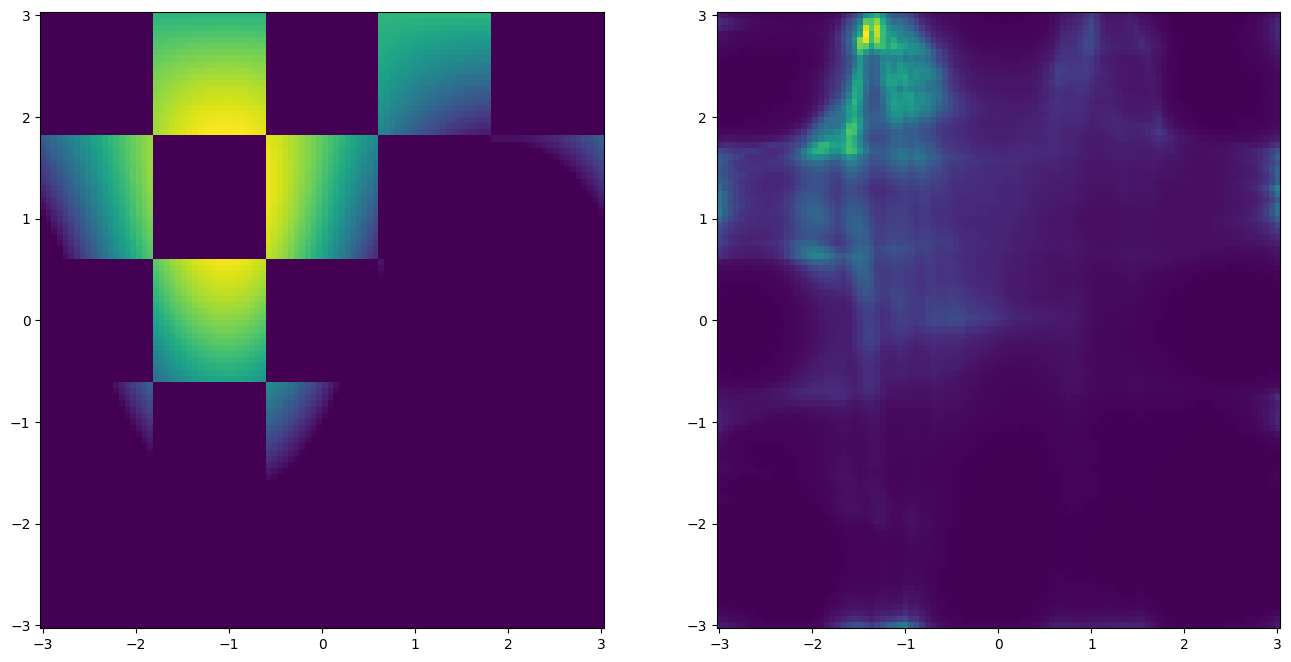

100%|██████████| 5000/5000 [16:50<00:00,  4.95it/s]


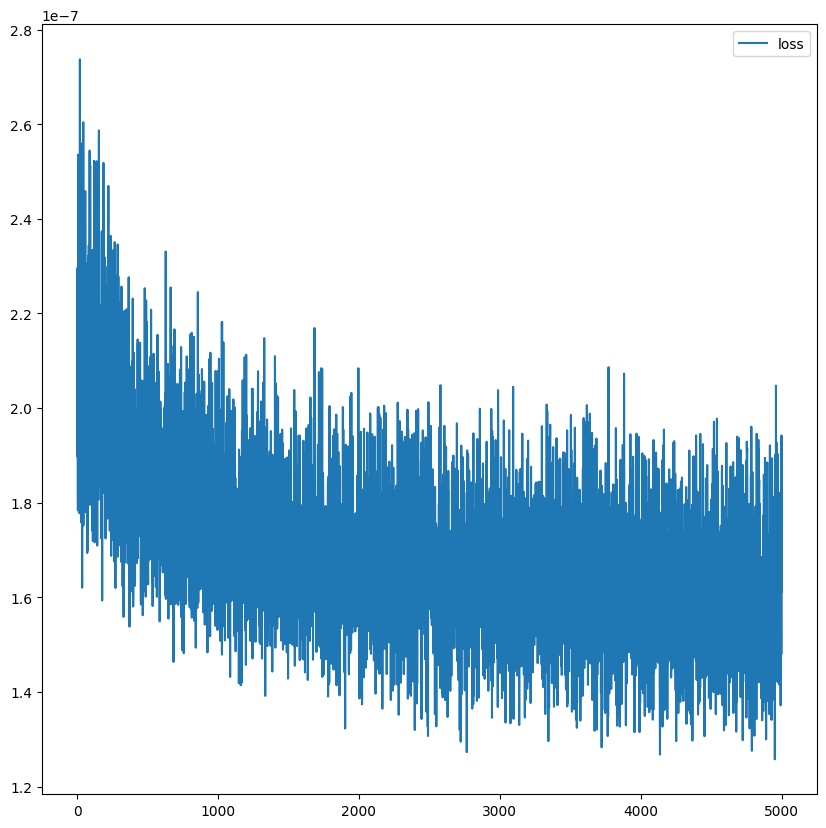

In [46]:
# Train model
max_iter = 5000
num_samples = 2 ** 12
show_iter = 1000


loss_hist = np.array([])

### This is without encoder/decoder
optimizer = torch.optim.AdamW(nfm.parameters(), lr=1e-4, weight_decay=1e-2)

for it in tqdm.tqdm(range(max_iter)):
    optimizer.zero_grad()

    unnorm = torch.rand(3, dtype=data_type, device = device) * 2 - 1
    normal = torch.divide(unnorm, torch.norm(unnorm))
    normals = normal.expand((num_samples, 3))

    """ ----- Sampling ----- """

    ### Sampling target for cross entropy loss 
    # x = nfm.p.sample(num_samples = num_samples, normals = normals).to(device).double()

    ### Test: Sampling Uniformly for D_KL Loss
    x = nfm.q0.sample(num_samples = num_samples).type(data_type)
    mr_grid_features = mrhEncoding(x)

    normals = normal.expand((*x.shape[: -1], ) + (normal.shape[0], ))

    # normal_enc = mrhEncoding_normal(normal.unsqueeze(0)).squeeze(0)
    # normals_enc = normal_enc.expand((*x.shape[: -1], ) + (normal_enc.shape[0], ))

    # model_input = torch.cat((normals_enc, mr_grid_features), dim = 1)
    model_input = torch.cat((normals, mr_grid_features), dim = 1)


    """ ----- Loss Calculation -----"""
    
    
    ### Test: Calculating D_KL as loss directly

    log_probs_p = nfm.p.log_prob(x, normals = normals)
    probs_q = torch.exp(log_probs_p)
    log_probs_q = nfm.log_prob(x, context = model_input)
    
    kl_divs = -probs_q * log_probs_q
    loss = torch.mean(kl_divs[~(torch.isnan(kl_divs) | torch.isinf(kl_divs))])


    if ~(torch.isnan(loss) | torch.isinf(loss)):
        loss.backward()
        optimizer.step()
        loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())
    

    # Plot learned distribution
    if (it + 1) % show_iter == 0:
        # compare_model_context_normal_enc(nfm, device, normal, mrhEncoding_normal, mrhEncoding)
        compare_model_context_normal(nfm, device, normal, mrhEncoding)

plt.figure(figsize=(10, 10))
plt.plot(loss_hist, label='loss')
plt.legend()
plt.show()